In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys, os, pickle
from scipy.optimize import curve_fit

current_dir = '/home/marian/CIGAR_ANALYSIS/CIGAR/notebooks'
functions_path = os.path.abspath(os.path.join(current_dir, '../functions'))
sys.path.append(functions_path)
import parse_data
import cigar as cig
from tqdm import tqdm

##  Signal time constants

In [46]:
# Wong (2011) colorblind-safe palette
CB_COLORS = [
    '#000000',  # Black
    '#E69F00',  # Orange
    '#56B4E9',  # Sky blue
    '#009E73',  # Bluish green
    '#F0E442',  # Yellow
    '#0072B2',  # Blue
    '#D55E00',  # Vermillion
    '#CC79A7',  # Reddish purple
    '#994F00',  # Brown
    '#006CD1',  # Cerulean
]

# Grayscale palette
GS_COLORS = [
    '#000000',  # Black
    '#1a1a1a',  # Near black
    '#333333',  # Very dark gray
    '#4d4d4d',  # Dark gray
    '#666666',  # Medium dark gray
    '#808080',  # Medium gray
    '#999999',  # Medium light gray
    '#b3b3b3',  # Light gray
    '#cccccc',  # Very light gray
    '#e6e6e6',  # Near white (use only on dark backgrounds)
]

# Classic palette — restores the original notebook look
CLASSIC_COLORS = [
    'royalblue', 'crimson', 'black', 'green',
    'darkorange', 'brown', 'coral', 'indigo', 'magenta', 'blue',
]

# colors = CB_COLORS
colors = GS_COLORS

CB_MARKERS    = ['o', 's', '^', 'D', 'v', 'P', '*', 'X']
CB_LINESTYLES = ['-', '--', '-.', ':', '-', '--', '-.', ':', '-', '--', '-.', ':']

In [47]:
font_size = 20
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['font.size'] = font_size

In [48]:
base = "/home/marian/CIGAR_ANALYSIS/CIGAR/data"

## Channel to study

Same recombination study as `TimeConstants_Suzuki_RecombinationTr.ipynb`, for a single channel. Change `channel` to
study another one.

In [49]:
channel  = 'CH2'                   # 'CH1' ... 'CH4'
ch_index = int(channel[2:]) - 1    # position of the channel in the mean-waveform files

##  Functions

In [50]:
def _rise_decay_normalised(t, t0, rise, decay):
    """Unit-area (1-exp)*exp pulse anchored at t0, zero for t < t0."""
    s = np.zeros_like(t, dtype=float)
    mask = t >= t0
    s[mask] = (1.0 - np.exp(-(t[mask]-t0) / rise)) * np.exp(-(t[mask]-t0) / decay)
    area = np.trapz(s, x=t)
    return s / (area if area != 0 else 1.0)

In [51]:
def ResponseSiPM(q_in_pes, t, t0, rise_time, decay_time, baseline=0.0):
    """SiPM single-PE pulse: area-normalised (1-exp)*exp, scaled by q_in_pes."""
    return q_in_pes * _rise_decay_normalised(t, t0, rise_time, decay_time) + baseline

In [52]:
def _check_bounds(popt, bounds_ch, label, names):
    """Check if any fitted parameter landed within 1% of its hard bounds."""
    tol = 0.01
    for i, (p, lo, hi) in enumerate(zip(popt, bounds_ch[0], bounds_ch[1])):
        span = (hi - lo) if not np.isinf(hi) else None
        if span is not None:
            if np.abs(p - lo) < tol * span:
                print(f'  ⚠ [{label}] {names[i]:12s} hit lower bound: value={p:.4e}  lower={lo:.4e}')
            elif np.abs(p - hi) < tol * span:
                print(f'  ⚠ [{label}] {names[i]:12s} hit upper bound: value={p:.4e}  upper={hi:.4e}')
        else:
            if p > 0 and np.abs(p - lo) / p < tol:
                print(f'  ⚠ [{label}] {names[i]:12s} hit lower bound: value={p:.4e}  lower={lo:.4e}')

In [53]:
def _I(p, q, u):
    """I(p,q,u) = integral_0^u exp(-p*s)*exp(-q*(u-s)) ds.
    Returns (exp(-p*u)-exp(-q*u))/(q-p) if p!=q, else u*exp(-p*u).
    """
    if np.abs(p - q) < 1e-30:
        return u * np.exp(-p * u)
    return (np.exp(-p * u) - np.exp(-q * u)) / (q - p)

In [54]:
def _conv_two_rise_decay(u, rise1, decay1, rise2, decay2):
    """Analytical convolution of two (1-exp)*exp pulses starting at u=0.
    h(u) = I(a,c,u) - I(a,d,u) - I(b,c,u) + I(b,d,u)
    with a=1/decay1, b=1/rise1+1/decay1, c=1/decay2, d=1/rise2+1/decay2.
    """
    a = 1.0 / decay1
    b = 1.0 / rise1 + 1.0 / decay1
    c = 1.0 / decay2
    d = 1.0 / rise2 + 1.0 / decay2
    return _I(a,c,u) - _I(a,d,u) - _I(b,c,u) + _I(b,d,u)

In [55]:
def recombination_model(t, t0, tau_rec, Tr):
    """Causal recombination model: (1-exp(-u/tau_rec))*(1+u/Tr)^2 for u=t-t0>0.
    No in-place mutation of t.
    """
    u    = t - t0
    mask = u > 0
    out  = np.zeros_like(t, dtype=float)
    out[mask] = (1.0 - np.exp(-u[mask] / tau_rec)) * (1.0 + u[mask] / Tr)**-2
    return out

In [56]:
def CIGARResponse_analytical(t, t0,
                             A_singlet, rise_singlet, tau_singlet,
                             A_triplet, rise_triplet, tau_triplet,
                             A_rec, tau_rec, Tr,
                             baseline=0.0):
    """CIGAR = singlet + triplet + recombination + baseline.
    SiPM shape fixed: rise=1 ns, decay=64 ns.
    Singlet and triplet rise/decay are FREE parameters.
    All convolution branches area-normalised before amplitude scaling.
    """
    sipm_rise  = 1e-9
    sipm_decay = 64e-9
    u    = t - t0
    mask = u > 0

    h_singlet       = np.zeros_like(t, dtype=float)
    h_singlet[mask] = _conv_two_rise_decay(u[mask], rise_singlet, tau_singlet, sipm_rise, sipm_decay)
    area = np.trapz(h_singlet, x=t)
    if area > 0: h_singlet *= A_singlet / area

    h_triplet       = np.zeros_like(t, dtype=float)
    h_triplet[mask] = _conv_two_rise_decay(u[mask], rise_triplet, tau_triplet, sipm_rise, sipm_decay)
    area = np.trapz(h_triplet, x=t)
    if area > 0: h_triplet *= A_triplet / area

    h_rec = recombination_model(t, t0, tau_rec, Tr)
    area = np.trapz(h_rec, x=t)
    if area > 0: h_rec *= A_rec / area

    return baseline + h_singlet + h_triplet + h_rec

In [57]:
def decay_tail(t, A, Tr, baseline):
    out = A*(1.0 + t / Tr)**-2 + baseline
    return out


def pm(value, error, unit=''):
    """'value ± error' with the error rounded to one significant figure and the value to the same decimal."""
    if not np.isfinite(error) or error <= 0:
        return f'{value:.3g}{unit}'
    d = -int(np.floor(np.log10(error)))
    if round(error, d) >= 10**(1 - d):   # e.g. 0.096 rounds to 0.1: one decimal fewer
        d -= 1
    return f'{round(value, d):.{max(d, 0)}f} ± {round(error, d):.{max(d, 0)}f}{unit}'


def fit_power_law(P, Tr_us):
    """T_r [us] = A * P[bar]^kappa: unweighted fit with the bounds and +-40% refinement used in this notebook.
    Returns popt = (A, kappa) and pcov."""
    fit_fn = lambda p, A, power: A * p**power
    bounds = ([0, -10], [np.inf, 0])
    popt, pcov = curve_fit(fit_fn, P, Tr_us, bounds=bounds, p0=[6e4, -2.7], maxfev=10_000)
    for _ in range(10):
        lo_r, hi_r = np.minimum(popt*0.6, popt*1.4), np.maximum(popt*0.6, popt*1.4)
        for i in range(2):
            if not (lo_r[i] <= popt[i] <= hi_r[i]):
                lo_r[i], hi_r[i] = bounds[0][i], bounds[1][i]
        popt, pcov = curve_fit(fit_fn, P, Tr_us, p0=popt, bounds=(lo_r, hi_r), maxfev=1_000, ftol=1e-12, xtol=1e-12)
    return popt, pcov


def decaying_part(P, Tr):
    """Mask of the pressures above the turnover of T_r(P), i.e. above the pressure with the largest T_r.
    Above it T_r falls with pressure as recombination predicts; below it T_r drops again as the pressure
    drops, so recombination no longer sets the tail (electrons escape)."""
    P, Tr = np.asarray(P), np.asarray(Tr)
    return P > P[np.nanargmax(Tr)]

In [58]:
from scipy.stats import gaussian_kde


def fit_cigar_waveforms(runs_dict, base,
                        pretrigger_sample=125,
                        t0_fit = 6e-6,
                        channels_to_show=None, invert=True,
                        colors=None, font_size=14, logscale=False, Tr_upper_factor=1.5):
    
    # 1. LOAD
    runs_fmt = {lbl: (f"Run{r}" if isinstance(r, int) else r) for lbl, r in runs_dict.items()}
    all_data = {lbl: np.load(f"{base}/mean_waveforms/mean_waveforms_{rn}.npz", allow_pickle=True)
                for lbl, rn in runs_fmt.items()}
    first_lbl = list(runs_fmt.keys())[0]
    channels  = all_data[first_lbl]["channels"]
    if channels_to_show is None:
        channels_to_show = list(range(len(channels)))

    # 2. FIGURE
    run_labels = ", ".join(f"{lbl} bar" for lbl in runs_fmt)
    if len(channels_to_show) == 1:
        fig, ax_single = plt.subplots(1, 1, figsize=(11, 8), dpi=150)
        axs = np.array([ax_single])
    else:
        fig, axs = plt.subplots(2, 2, figsize=(20, 14), dpi=150)
    
    cigar_params = {}

    for plot_i, ch_idx in enumerate(channels_to_show[:4]):
        ax       = axs.flat[plot_i]
        ch       = channels[ch_idx]
        sphe_key = f"CH{ch_idx + 1}"

        # 3. LOAD & OVERPLOT ALL RUNS
        wf_target, time_fit = None, None
        for ii, (lbl, rn) in enumerate(runs_fmt.items()):
            wf = all_data[lbl][f"ch_{ch}"].copy()
            t  = all_data[lbl]["time"]
            if invert: wf = -wf
            if ii == 0: wf_target, time_fit = wf, t
            pressure_in_bar  = lbl
            pressure_in_torr = pressure_in_bar * 750.062
            ax.plot(t * 1e6, wf, "-o", lw=2, color=colors[ch_idx], alpha=0.55,
                    label=f"{lbl} bar data")
    
    
        # 4. PRETRIGGER
        t0_fixed  = t0_fit

        # 5. FIT REGION
        fit_mask = time_fit >= t0_fixed
        t_fit    = time_fit[fit_mask]
        wf_fit   = wf_target[fit_mask]

        # 6. BASELINE + Tr GUESS
        # baseline_est = np.abs(np.mean(wf_target[:pretrigger_sample]))
        # baseline_est = np.mean(wf_target[:pretrigger_sample])
        # mode of the pretrigger samples: peak of a smooth density estimate (robust to skewed pretrigger noise)
        pre          = wf_target[:pretrigger_sample]
        grid         = np.linspace(pre.min(), pre.max(), 2001)
        baseline_est = grid[np.argmax(gaussian_kde(pre)(grid))]
        baseline_est_err = np.std(wf_target[:pretrigger_sample])/np.sqrt(pretrigger_sample)
        # Tr from Suzuki (2015): Tr [s] = 6e4 * P[Torr]^(-2.7)
        Tr_guess = 6e4 * pressure_in_torr**(-2.7)
        print(f"  {sphe_key} @ {pressure_in_bar:.1f} bar:  Tr_guess = {Tr_guess*1e6:.2f} µs")
        A_tot = max(np.trapz(wf_fit, x=t_fit),
                    wf_fit.max() * (t_fit[-1] - t_fit[0]) * 0.1)
        

        # 9. FIT FUNCTION
        def fit_fn(t, A, Tr):
            return decay_tail(t, A, Tr, baseline_est)
        
        # p0_ch = [A_tot, Tr_guess, baseline_est]
        p0_ch = [A_tot, Tr_guess]


        # lower = [0, 0, baseline_est*0.99] # A, Tr, baseline
        # upper = [np.inf, Tr_guess*1.5, baseline_est*1.01] # A, Tr, baseline
        lower = [0, 0] # A, Tr
        upper = [np.inf, Tr_guess*Tr_upper_factor] # A, Tr  (cap on T_r: 1.5 x Suzuki by default)
        bounds_ch = (lower, upper)

        N_PARAMS = len(lower)


        try:
            # broad fit in scaled space
            popt, pcov = curve_fit(fit_fn, t_fit, wf_fit,
                                   bounds = bounds_ch,
                                   p0=p0_ch, maxfev=10_000)
            

            # refinement: ±40%, clipped to hard bounds, in scaled space
            for _ in range(10):
                lo_r = np.minimum(popt * 0.6, popt * 1.4)
                hi_r = np.maximum(popt * 0.6, popt * 1.4)

                lo_r[-1] = np.minimum(popt[-1] * 0.99, popt[-1] * 1.01)
                hi_r[-1] = np.maximum(popt[-1] * 0.99, popt[-1] * 1.01)
                
                for i in range(N_PARAMS):
                    if not (lo_r[i] <= popt[i] <= hi_r[i]):
                        lo_r[i] = bounds_ch[0][i]
                        hi_r[i] = bounds_ch[1][i]
                popt, pcov = curve_fit(fit_fn, t_fit, wf_fit,
                                    p0=popt, bounds=(lo_r, hi_r),
                                    maxfev=1_000, ftol=1e-12, xtol=1e-12)
                
                perr, fit_ok = np.sqrt(np.diag(pcov)), True

        except RuntimeError as e:
            print(f"[{sphe_key}] CIGAR fit failed: {e}")
            popt, pcov   = np.array(p0_ch), np.full((N_PARAMS, N_PARAMS), np.nan)
            perr, fit_ok = np.full(N_PARAMS, np.nan), False

        # (A, Tr, bl) = popt
        (A, Tr) = popt

        cigar_params[sphe_key] = dict(
             A=A
            ,Tr=Tr
            ,baseline=baseline_est   
            ,pcov=pcov
        )

        y_fit = fit_fn(t_fit, *popt)

        # 12. PLOT
        if fit_ok:
            ax.plot(t_fit * 1e6, y_fit,
                    color="red", lw=2, ls="-", zorder=5,
                    label=r"Tail fit: $A\,(1 + t/T_r)^{-2} + \mathrm{bl}$" + "\n"
                          + fr"$T_r$ = {pm(Tr*1e6, perr[1]*1e6)} $\mu$s" + "\n"
                          + fr"bl (fixed) = {pm(baseline_est, baseline_est_err)} mV")

            # ax.fill_between(t_fit*1e6, bl, y_fit, alpha=0.2, color='r')
            ax.fill_between(t_fit*1e6, baseline_est, y_fit, alpha=0.2, color='r')

            
        ax.set_title(f"{sphe_key}, {run_labels}", fontsize=font_size * 0.7)
        ax.set_ylabel("Amplitude [mV]", fontsize=font_size * 0.85)
        ax.set_xlabel("Time [\u00b5s]", fontsize=font_size * 0.85)
        ax.legend(loc="upper right", fontsize=font_size * 0.65)
        ax.set_xlim(0, t.max() * 1e6)

        if logscale:
            ax.set_yscale("log")
            # from just below the lowest positive value of the fitted tail to above the pulse peak
            ax.set_ylim(0.5 * wf_fit[wf_fit > 0].min(), wf_target.max() * 2)

        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    # plt.show()
    return fig, axs, cigar_params

##  CIGAR's response model

In [59]:
pretrigger  = 100

##  Signal time constants

In [60]:
# All runs per gas: every pressure is fitted and plotted; only the decaying part of T_r(P) (above its turnover,
# see decaying_part) is used for the power law
RUNS_BY_GAS   = {'Ar': {8.5: 'Run171', 7.5: 'Run173', 6.5: 'Run175', 5.5: 'Run177',
                        4.5: 'Run179', 3.5: 'Run181', 2.5: 'Run183', 1.5: 'Run185'},
                 'Xe': {8.5: 'Run75',  7.5: 'Run77',  6.5: 'Run90',  5.5: 'Run83',
                        4.5: 'Run103', 3.5: 'Run105', 2.5: 'Run111', 1.5: 'Run114'}}
T0_FIT_BY_GAS = {'Ar': 6e-6, 'Xe': 4e-6}   # tail fit start on the plot time axis [s]

gas    = 'Xe'
runs   = RUNS_BY_GAS[gas]
t0_fit = T0_FIT_BY_GAS[gas]

In [61]:
example_pres = 8.5

  CH2 @ 8.5 bar:  Tr_guess = 3.21 µs


/tmp/ipykernel_6281/1942984501.py:66: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  A_tot = max(np.trapz(wf_fit, x=t_fit),


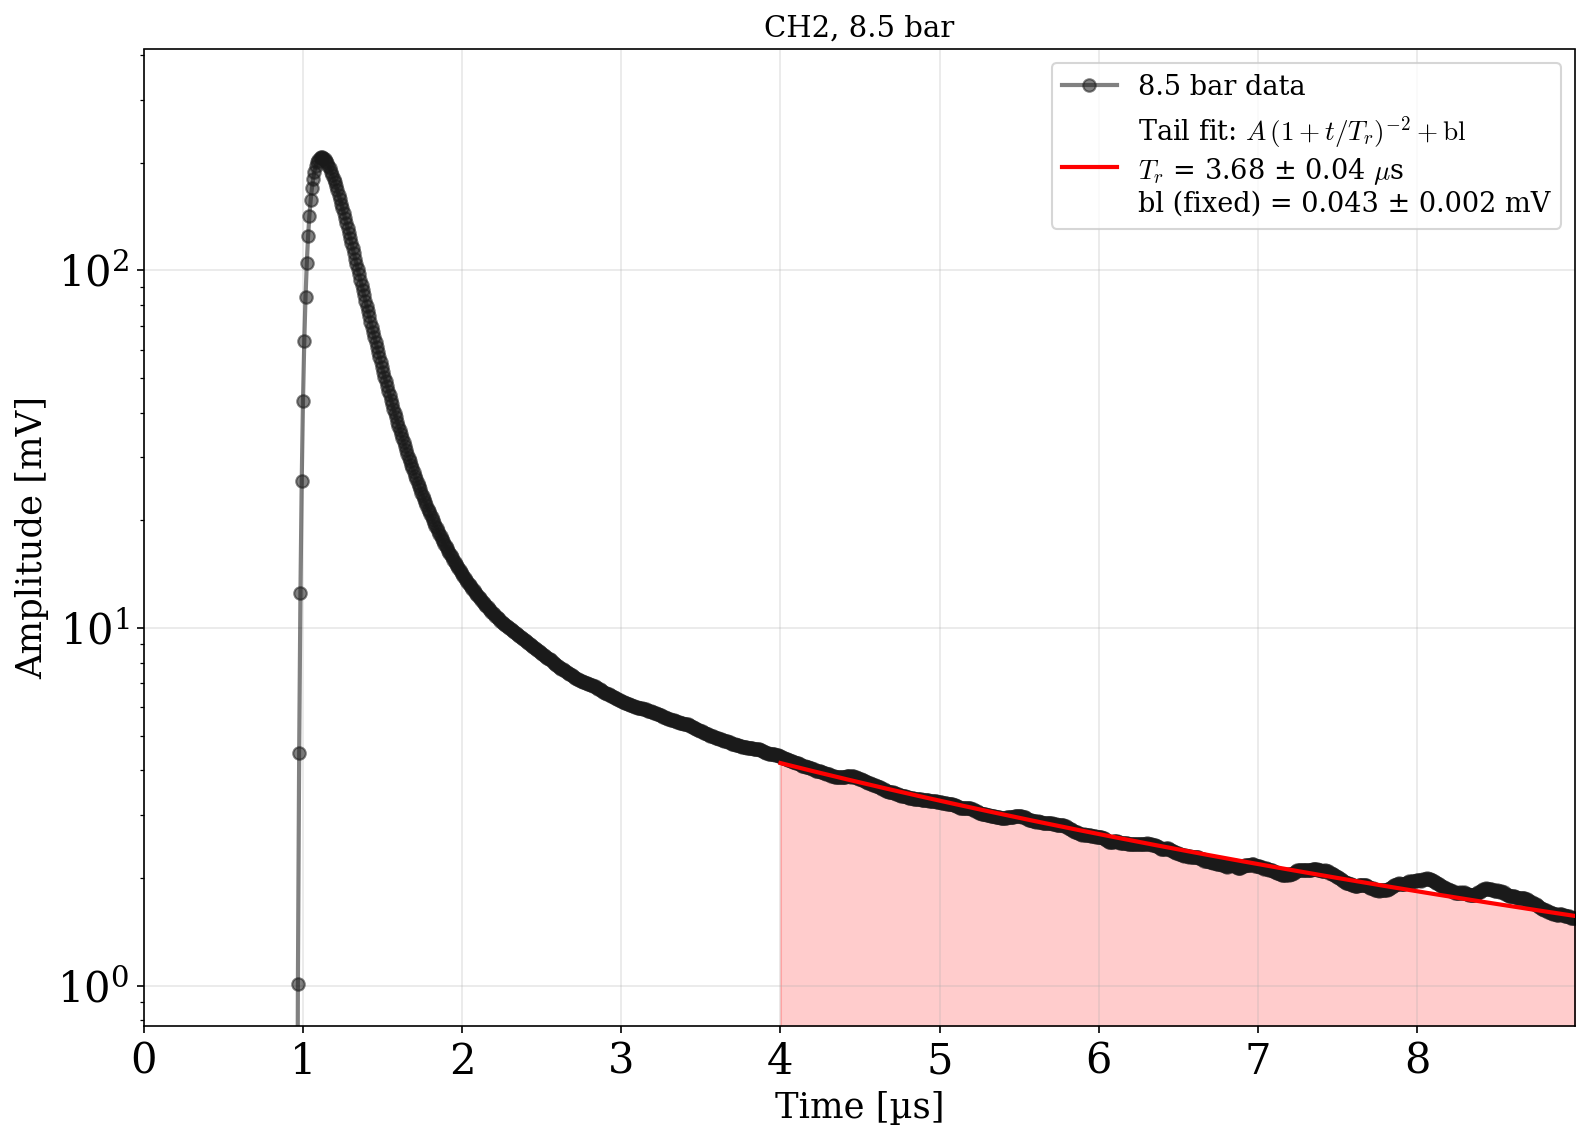

In [62]:
fig_cig, axs, cigar_params = fit_cigar_waveforms({example_pres:runs[example_pres]}, 
                                                 base, pretrigger_sample=pretrigger,
                                                 t0_fit = t0_fit,
                                                 channels_to_show=[ch_index], invert=True,
                                                 colors=colors, font_size=20, logscale=True)

# for ax in axs.flatten():
#     # ax.set_ylim(1, 30)
#     ax.set_ylim(-1, 1.5)
#     ax.set_xlim(0, 1)
    
plt.show()

In [63]:
check_aprox_validity = False

  CH2 @ 8.5 bar:  Tr_guess = 3.21 µs


/tmp/ipykernel_6281/1942984501.py:66: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  A_tot = max(np.trapz(wf_fit, x=t_fit),


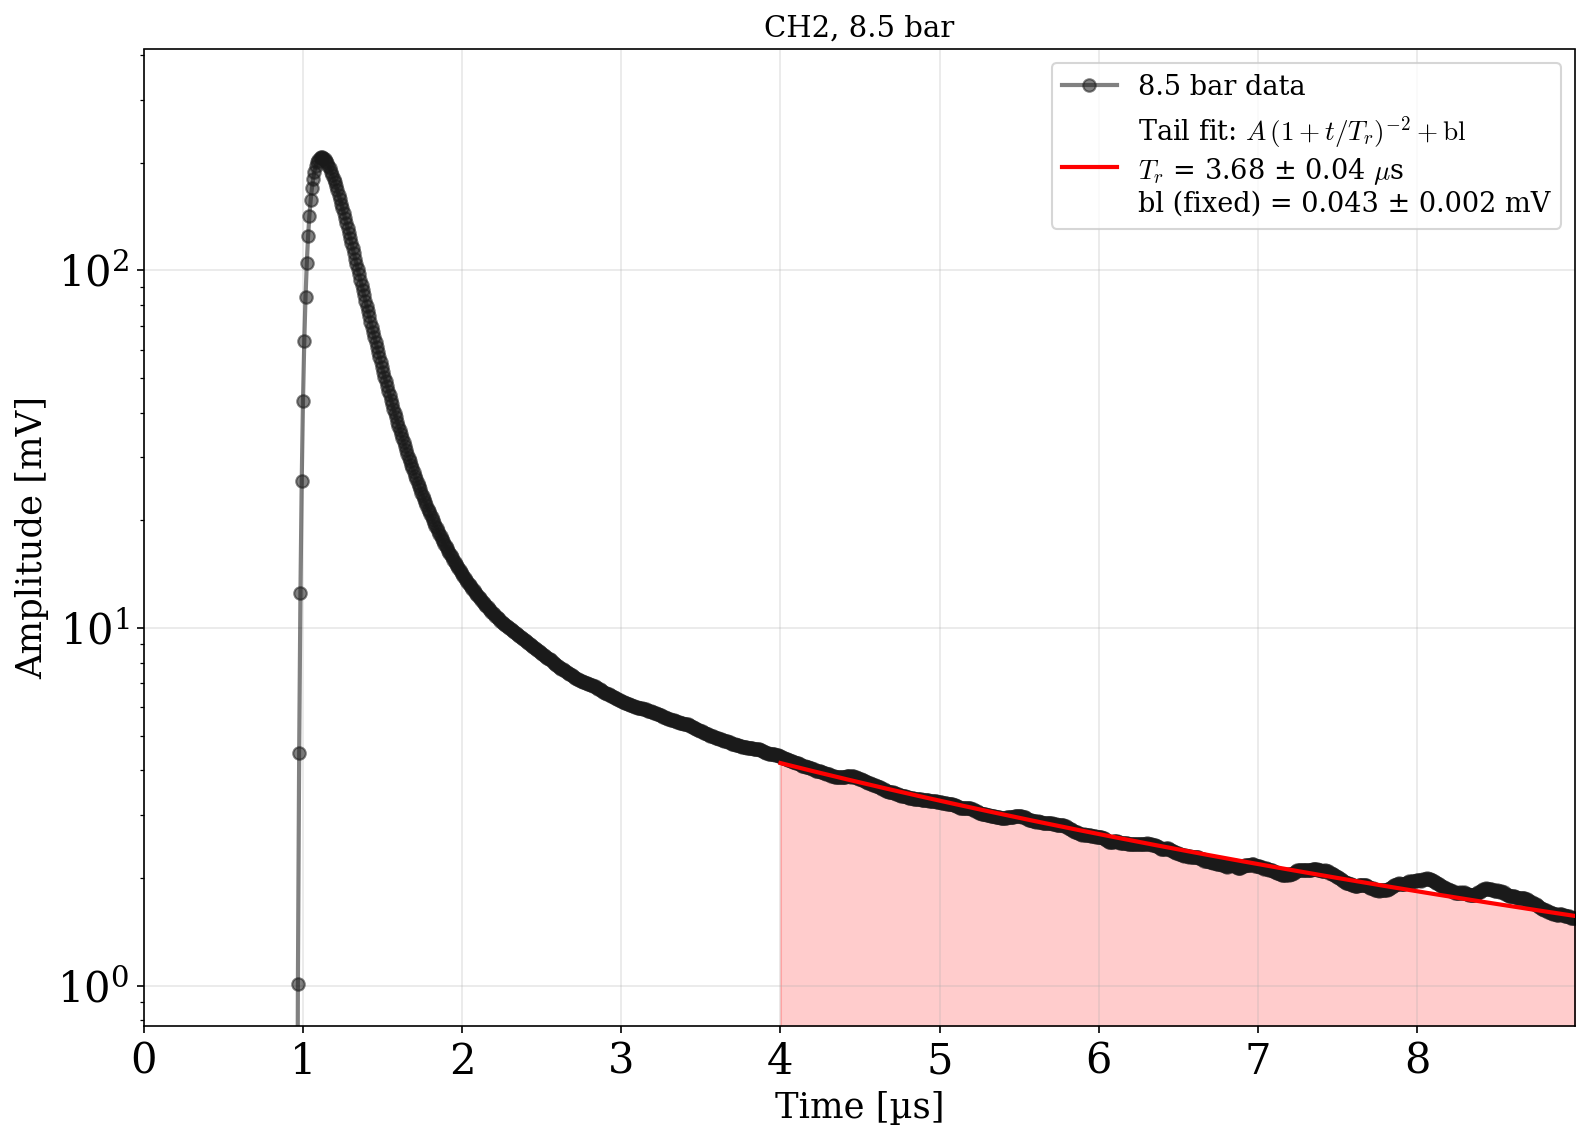

  ⚠ [CH2] 8.5 bar — pcov ill-conditioned (cond=4.5e+15), errors unreliable
  CH2 @ 7.5 bar:  Tr_guess = 4.49 µs


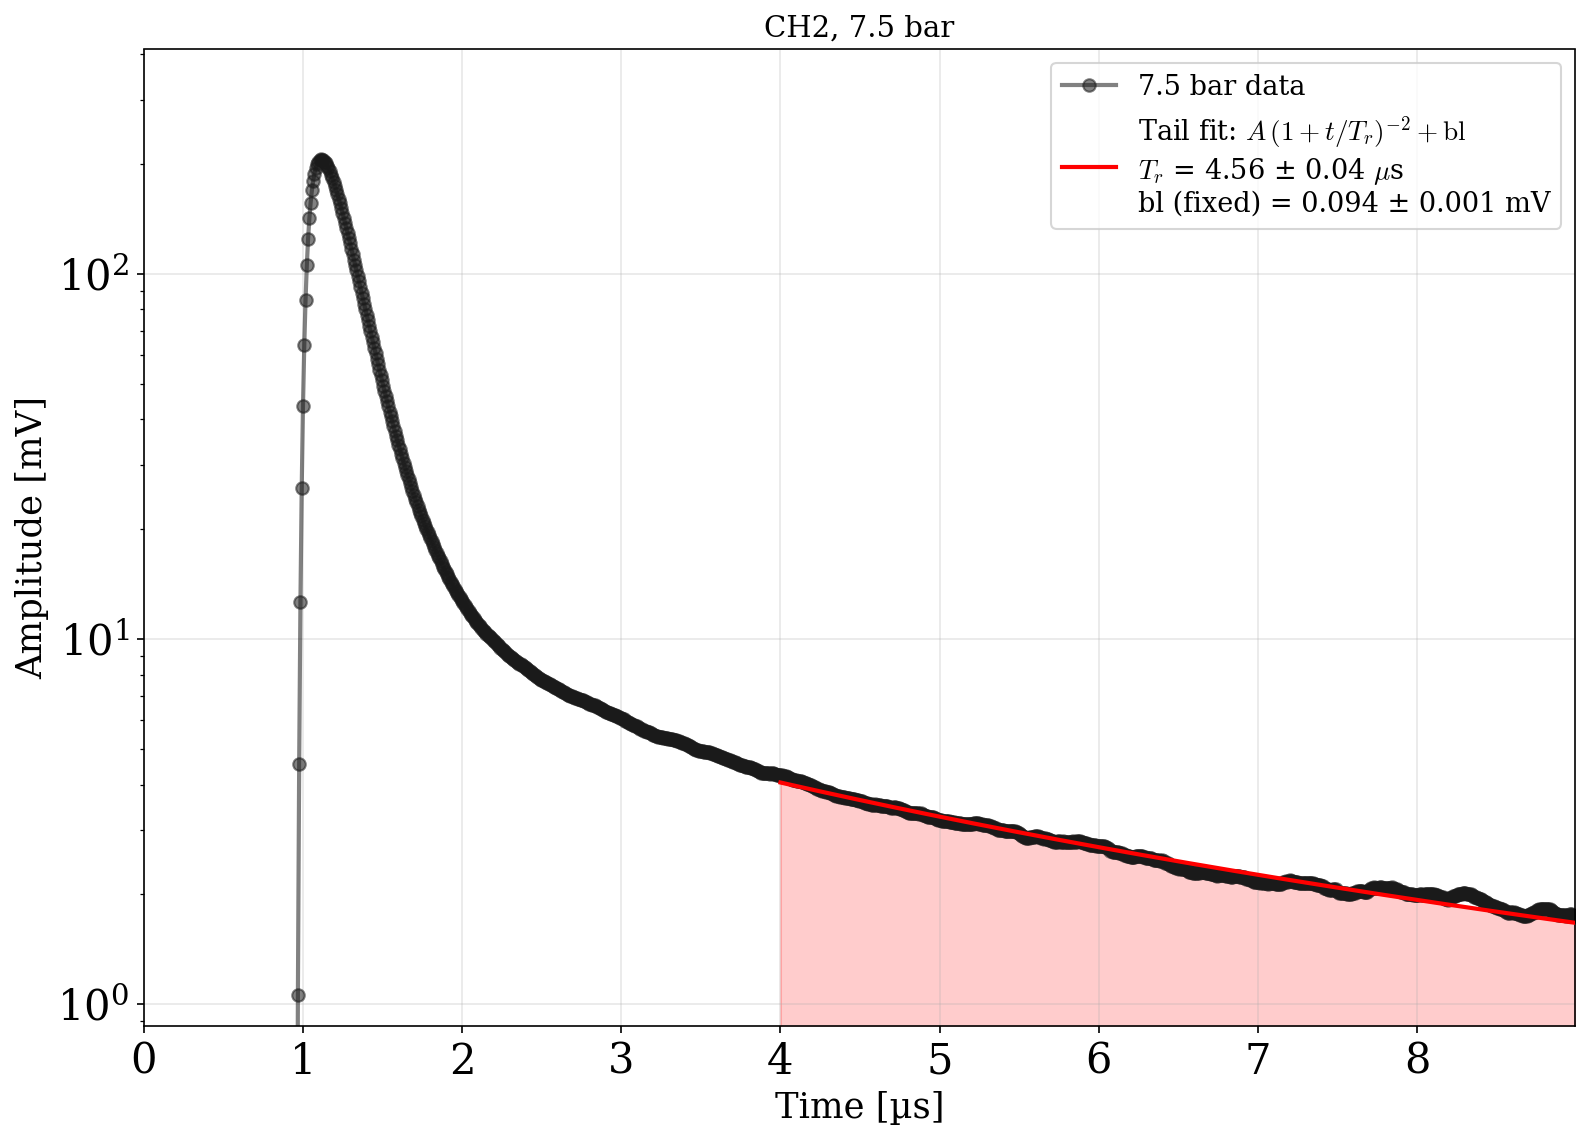

  ⚠ [CH2] 7.5 bar — pcov ill-conditioned (cond=1.1e+15), errors unreliable
  CH2 @ 6.5 bar:  Tr_guess = 6.61 µs


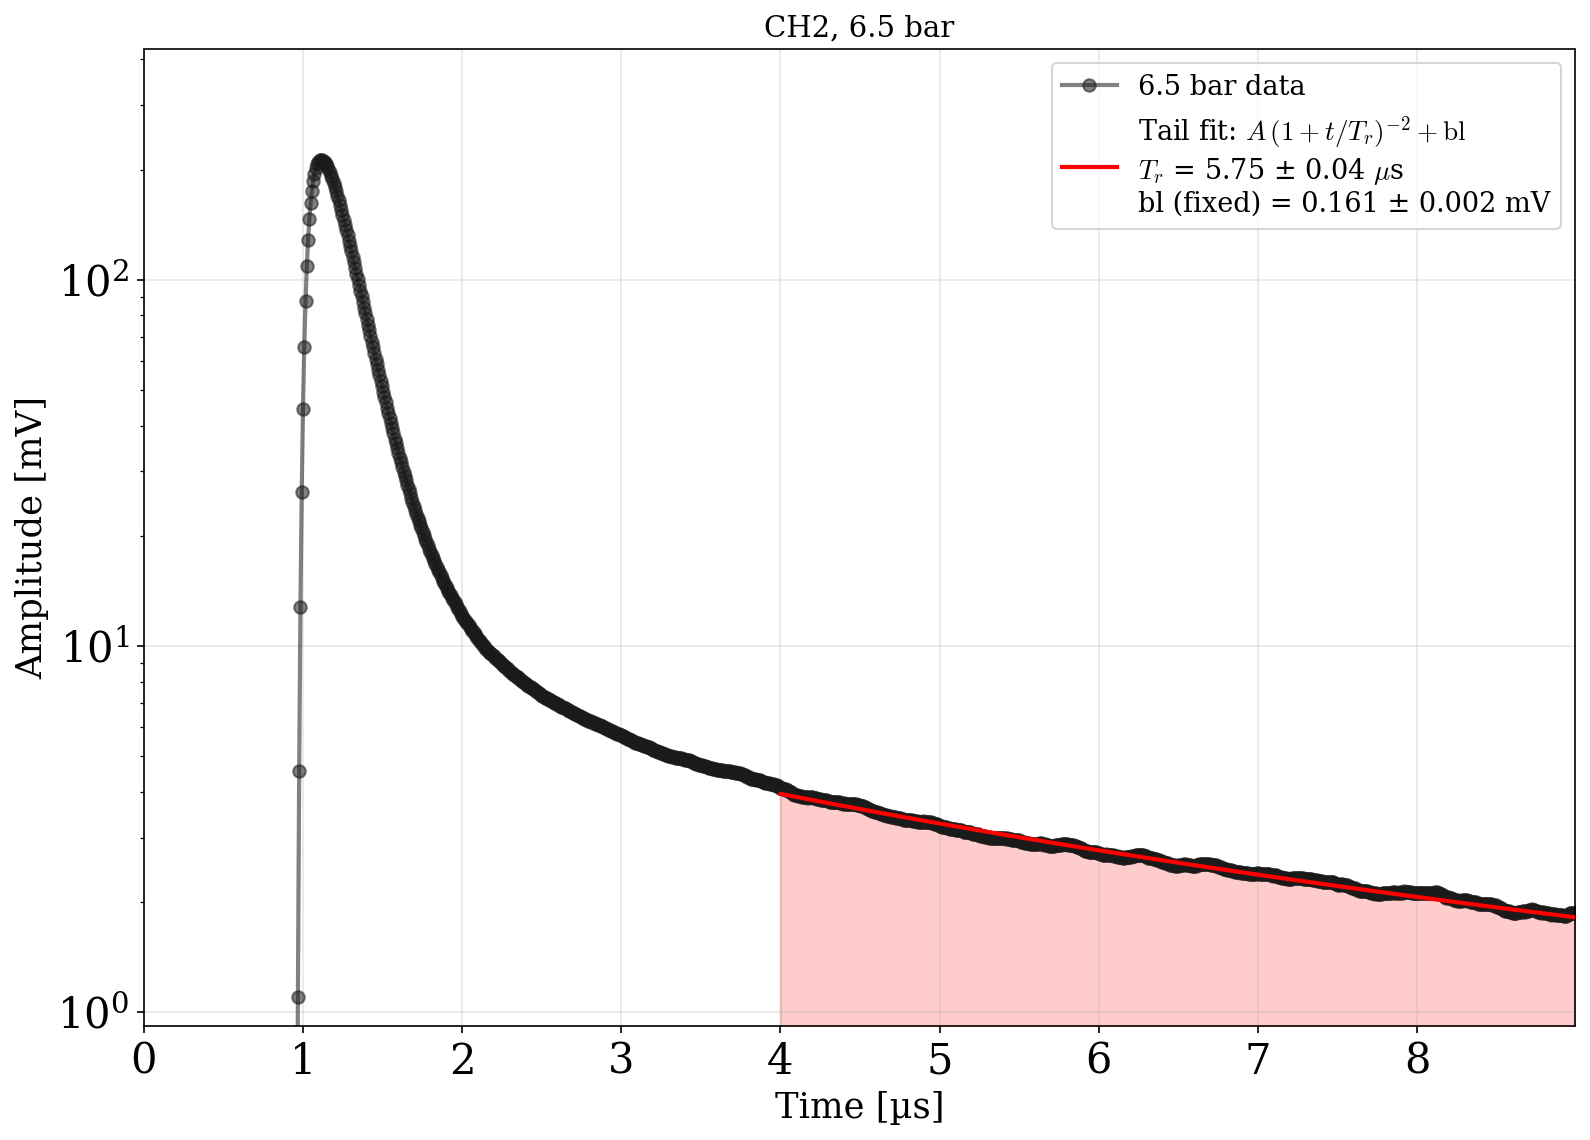

  ⚠ [CH2] 6.5 bar — pcov ill-conditioned (cond=2.8e+14), errors unreliable
  CH2 @ 5.5 bar:  Tr_guess = 10.39 µs


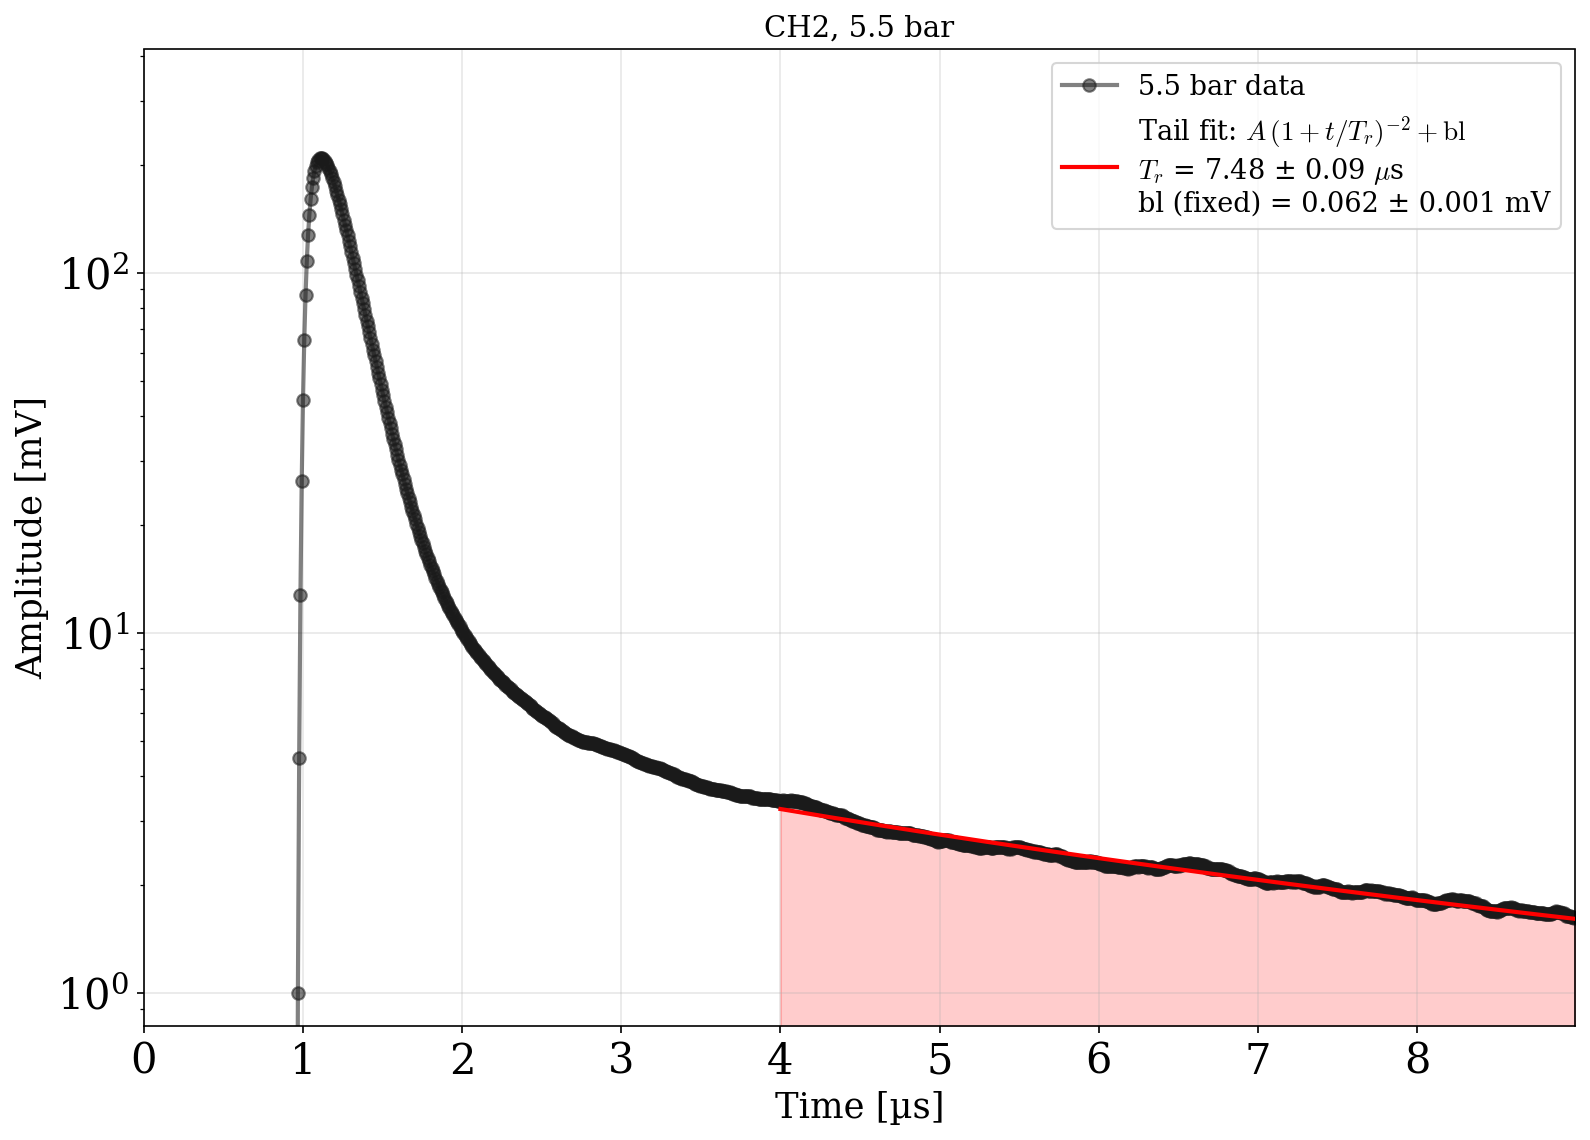

  ⚠ [CH2] 5.5 bar — pcov ill-conditioned (cond=4.7e+13), errors unreliable
  CH2 @ 4.5 bar:  Tr_guess = 17.85 µs


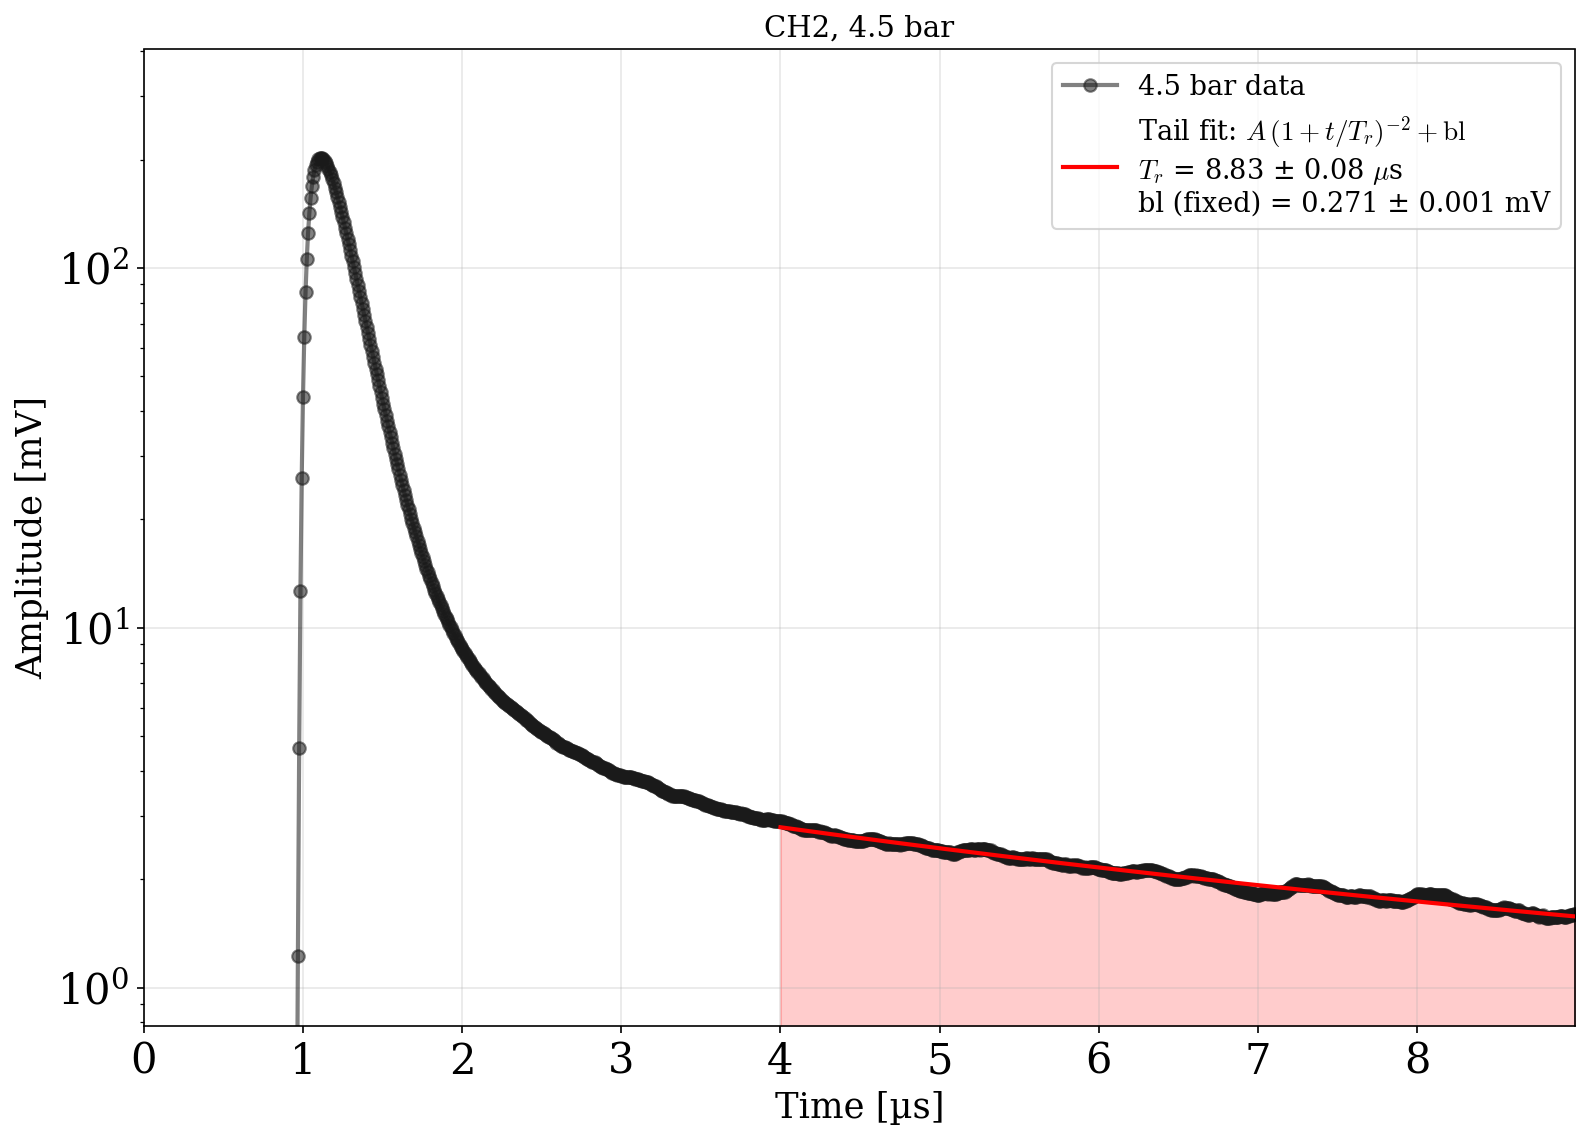

  ⚠ [CH2] 4.5 bar — pcov ill-conditioned (cond=1.2e+13), errors unreliable
  CH2 @ 3.5 bar:  Tr_guess = 35.19 µs


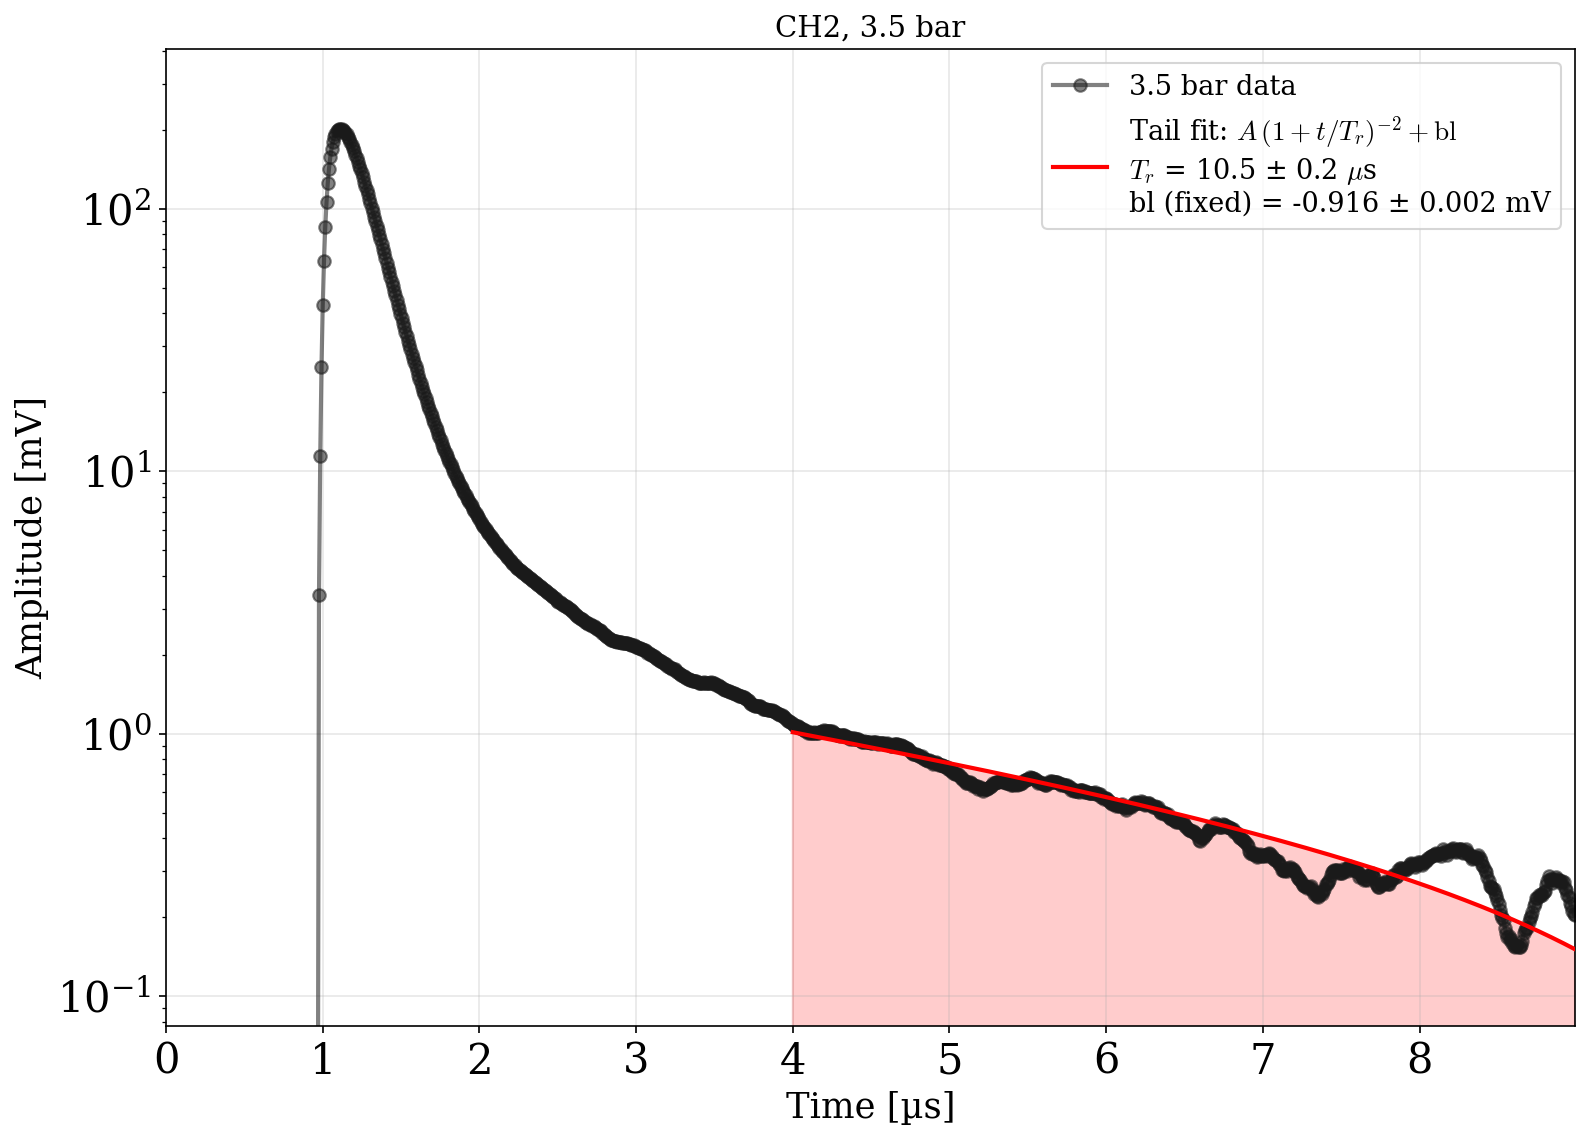

  ⚠ [CH2] 3.5 bar — pcov ill-conditioned (cond=3.1e+12), errors unreliable
  CH2 @ 2.5 bar:  Tr_guess = 87.29 µs


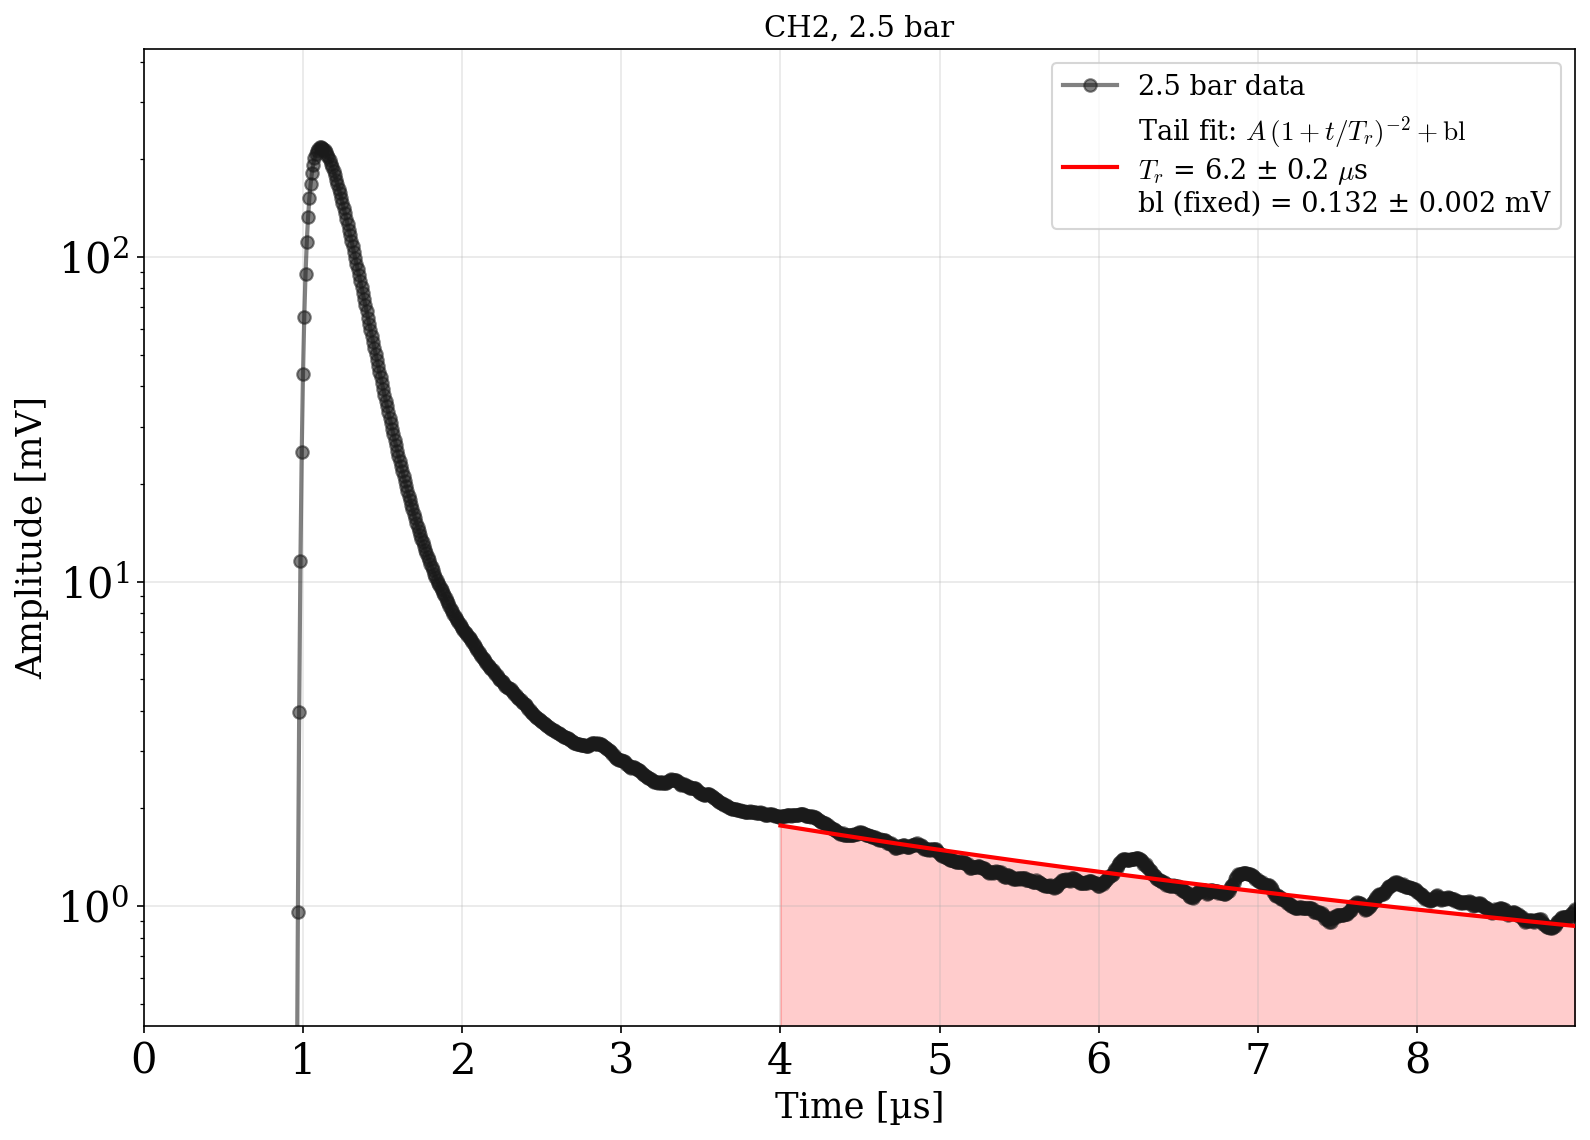

  ⚠ [CH2] 2.5 bar — pcov ill-conditioned (cond=3.6e+13), errors unreliable
  CH2 @ 1.5 bar:  Tr_guess = 346.69 µs


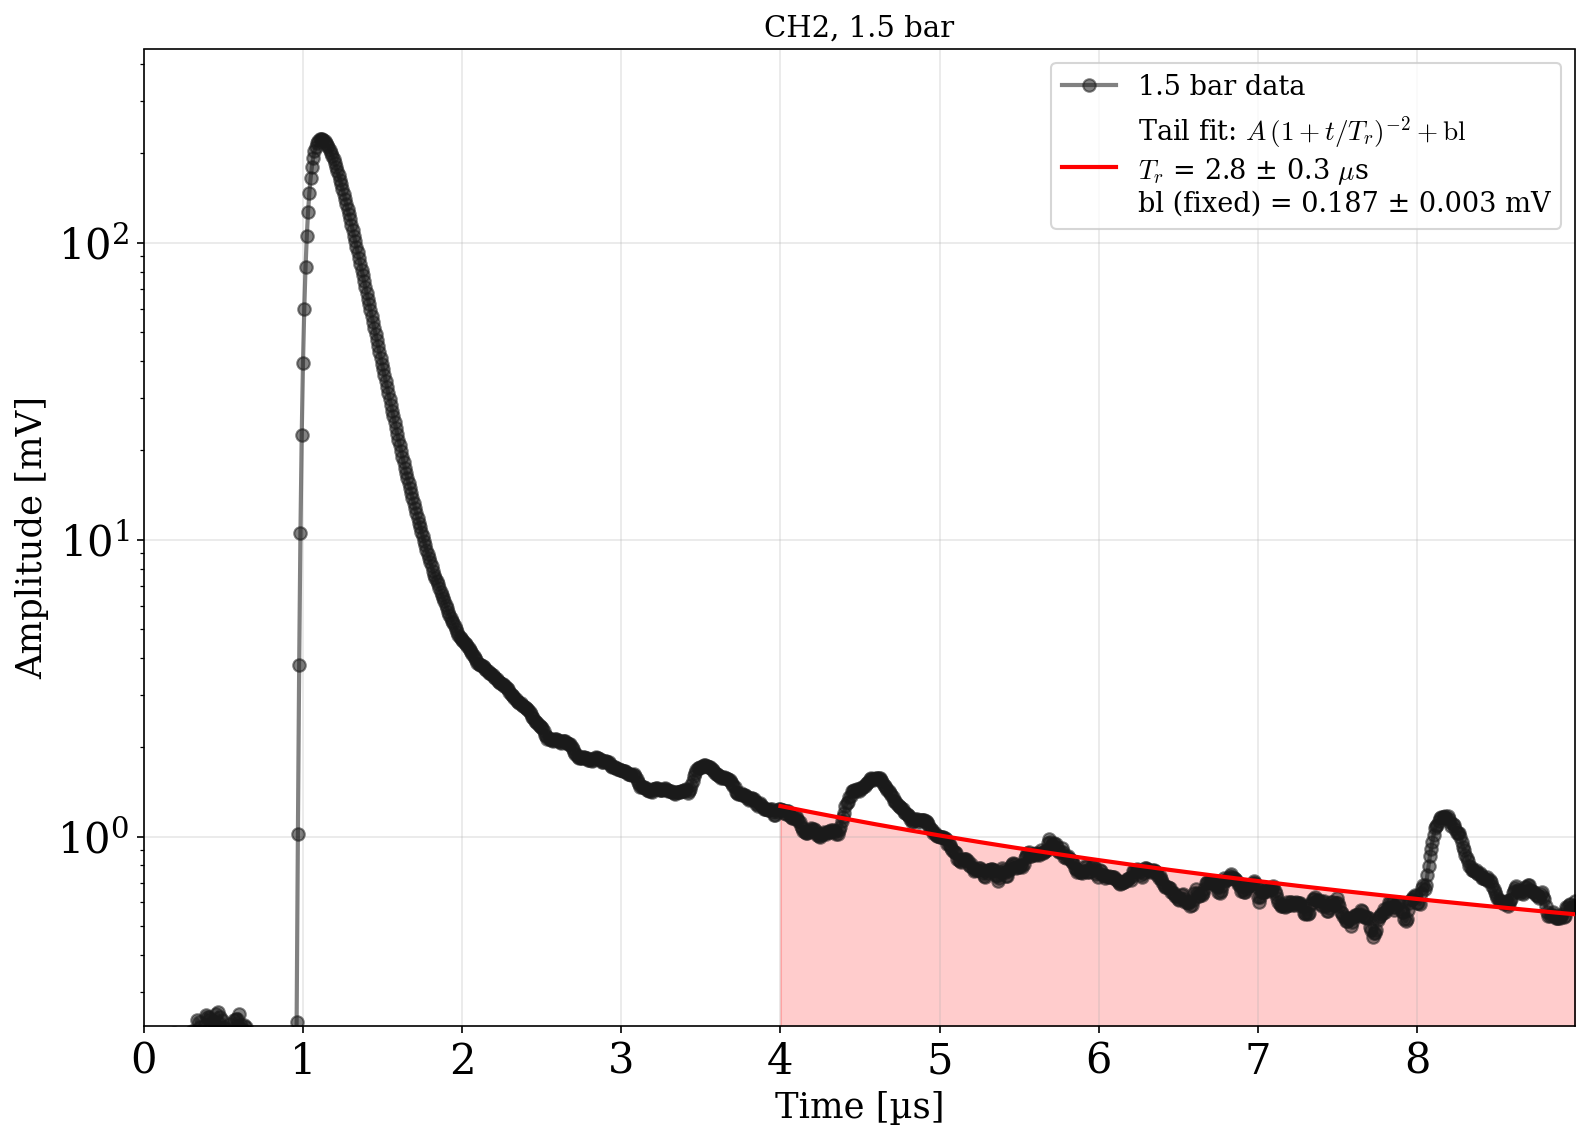

  ⚠ [CH2] 1.5 bar — pcov ill-conditioned (cond=1.6e+15), errors unreliable

DONE!


In [64]:
# singlet, triplet, recombination per channel per pressure
rec_A, rec_Tr, rec_bl = {}, {}, {}

# Store waveform/fit arrays for the final summary figure
all_fits = {}  # {bars: {sphe_key: {t_fit, wf_fit, wf_model, h_singlet, h_triplet, h_rec, bl, fit_ok}}}

prev_cp = None  # warm-start from previous (higher) pressure


for bars, run_name in sorted(runs.items(), reverse=True):   # 8.5 -> 1.5 bar
    run = {bars: run_name}


    fig, axs_cig, cp = fit_cigar_waveforms(run, base, pretrigger_sample=pretrigger,
                                           t0_fit=t0_fit,
                                           channels_to_show=[ch_index], invert=True,
                                           colors=colors, font_size=20, logscale=True
                                           )
    plt.show()

    # reload raw waveforms and reconstruct branches for summary figure
    run_name_fmt = run_name if not isinstance(run_name, int) else f"Run{run_name}"
    npz          = np.load(f"{base}/mean_waveforms/mean_waveforms_{run_name_fmt}.npz", allow_pickle=True)
    channels_arr = npz["channels"]
    time_arr     = npz["time"]
    all_fits[bars] = {}

    for ch_idx, ch in enumerate(channels_arr):
        sk = f"CH{ch_idx+1}"
        if sk not in cp: continue
        p    = cp[sk]
        wf   = -npz[f"ch_{ch}"].copy()
        fit_mask = time_arr >= t0_fit
        t_fit    = time_arr[fit_mask]
        wf_fit   = wf[fit_mask]

        A, Tr_ = p["A"], p["Tr"]
        bl = p["baseline"]


        # 9. FIT FUNCTION
        def fit_fn(t, A, Tr):
            return decay_tail(t, A, Tr, bl)

        wf_model = decay_tail(t_fit, A, Tr_, bl)

        all_fits[bars][sk] = dict(t = time_arr, wf = wf,
                                  t_fit=t_fit, wf_fit=wf_fit, wf_model=wf_model,
                                  bl=bl, fit_ok=not np.any(np.isnan(p["pcov"])),
                                  )

    # accumulate decay-time tables
    # NOTE: _e is defined as a local function with explicit argument capture
    # to avoid the Python closure-over-loop-variable bug (all closures
    # defined inside a loop share the same 'cov' reference otherwise).
    for ch in cp:
        cov  = cp[ch]["pcov"]
        cond = np.linalg.cond(cov) if not np.any(np.isnan(cov)) else np.inf
        if np.any(np.isnan(cov)):
            print(f"  ✗ [{ch}] {bars} bar — fit failed, errors are NaN")
        elif cond > 1e8:
            print(f"  ⚠ [{ch}] {bars} bar — pcov ill-conditioned (cond={cond:.1e}), errors unreliable")

        if ch not in rec_Tr:
            rec_A[ch]   = {}; rec_Tr[ch]    = {}
            rec_bl[ch]  = {}

        def _safe_err(cov_mat, idx):
            """Extract sqrt(cov[idx,idx]), returning nan if not finite."""
            val = cov_mat[idx, idx]
            return float(np.sqrt(val)) if np.isfinite(val) and val >= 0 else float('nan')

        rec_A[ch][bars]     = (cp[ch]["A"],     _safe_err(cov, 0))
        rec_Tr[ch][bars]    = (cp[ch]["Tr"],    _safe_err(cov, 1))
        rec_bl[ch][bars]    = (cp[ch]["baseline"],    _safe_err(cov, 1))



print("\nDONE!")

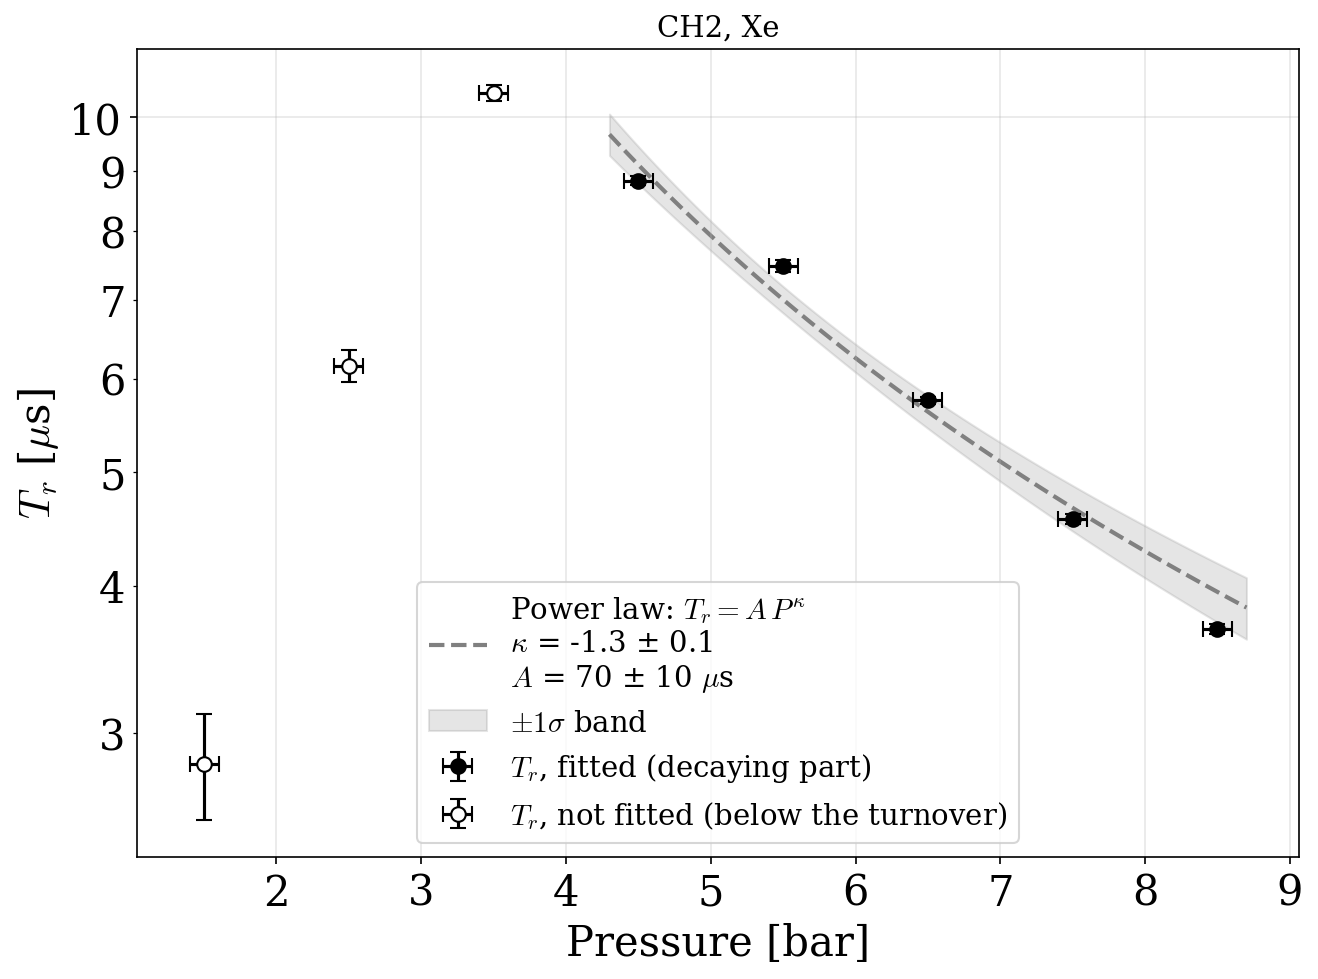

In [65]:
# Decay times vs pressure — always in B&W for publication clarity.
# All pressures are shown; the power law is fitted only to the decaying part (filled), the rest is open.
_gs = GS_COLORS

channels_to_show = [channel]

if len(channels_to_show) > 1:
    fig_sum, axs = plt.subplots(2, 2, figsize=(20, 14), dpi=150)
else:
    fig_sum, axs = plt.subplots(1, 1, figsize=(10, 7), dpi=150)

for ii, ch in enumerate(channels_to_show):
    ax = axs.flat[ii] if np.size(axs) > 1 else axs

    bars_list    = np.array(sorted(rec_Tr[ch].keys()))
    Tr_rec_vals  = np.array([rec_Tr[ch][b][0] for b in bars_list]) * 1e6   # [us]
    err_rec_vals = np.array([rec_Tr[ch][b][1] for b in bars_list]) * 1e6   # [us]
    used         = decaying_part(bars_list, Tr_rec_vals)

    for sel, label, mfc in ((used,  r'$T_r$, fitted (decaying part)', _gs[0]),
                            (~used, r'$T_r$, not fitted (below the turnover)', 'white')):
        ax.errorbar(bars_list[sel], Tr_rec_vals[sel], yerr=err_rec_vals[sel], xerr=0.1,
                    fmt='o', color=_gs[0], mfc=mfc, capsize=4, markersize=7, label=label)

    (A_fit, power_fit), pcov = fit_power_law(bars_list[used], Tr_rec_vals[used])
    A_err, power_err         = np.sqrt(np.diag(pcov))

    p_fit = np.linspace(bars_list[used].min() - 0.2, bars_list[used].max() + 0.2, 100)
    y_fit = A_fit * p_fit**power_fit
    dfdA     = p_fit**power_fit
    dfdpower = A_fit * p_fit**power_fit * np.log(p_fit)
    y_std    = np.sqrt(dfdA**2 * pcov[0, 0] + dfdpower**2 * pcov[1, 1] + 2 * dfdA * dfdpower * pcov[0, 1])

    ax.plot(p_fit, y_fit, color='grey', lw=2, ls='--', zorder=1,
            label=r'Power law: $T_r = A\,P^{\kappa}$' + '\n' + fr'$\kappa$ = {pm(power_fit, power_err)}'
                  + '\n' + fr'$A$ = {pm(A_fit, A_err)} $\mu$s')
    ax.fill_between(p_fit, y_fit - y_std, y_fit + y_std, color='grey', alpha=0.2, label=r'$\pm 1\sigma$ band')

    ax.set_title(f'{ch}, {gas}', fontsize=font_size*0.7)
    ax.set_xlabel('Pressure [bar]', fontsize=font_size)
    ax.set_ylabel(r'$T_r$ [$\mu$s]', fontsize=font_size)
    ax.grid(True, alpha=0.3)
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:g}'))   # plain numbers on the log axis
    ax.yaxis.set_minor_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:g}'))
    ax.legend(fontsize=font_size*0.7, loc='lower center')   # empty corner between the low and high pressures

plt.show()

## Stability of $\kappa$ ($T_r \propto P^\kappa$): pressure range, fit start, time origin and channel

Everything below reuses `fit_cigar_waveforms` and `fit_power_law`; only the fit start, the pressures used, the time origin, the $T_r$ upper bound and the channel change. Errors are rounded to one significant figure.

- **Pressure range**: all pressures are fitted, but $\kappa$ uses only the *decaying part* of $T_r(P)$: the pressures above its turnover (largest $T_r$). Below the turnover $T_r$ drops again as the pressure drops, and the share of late light falls, so recombination no longer sets the tail. `Xe, P≥5 bar` is kept as a fixed-range comparison.
- **Fit start**: `t0_fit` is on the plot time axis, scanned from 2 to 8 µs in 0.2 µs steps. The record ends at 9 µs, so a fit starting at 8 µs only sees 1 µs of tail.
- **Baseline**: fixed to the mode of the pretrigger samples (peak of a kernel density estimate).
- **Time origin**: `decay_tail` counts $t$ from the start of the record, not from the onset $t_{on}$ (`T_ONSET` = 0.5 µs). Since $A(1+t/T_r)^{-2} = A'(1+(t-t_{on})/T_r')^{-2}$ with $T_r' = T_r + t_{on}$, the onset-referenced value is exactly $T_r + t_{on}$; no refit needed.
- **Upper bound**: each tail fit caps $T_r$ at 1.5 × the Suzuki (2015) expectation; `Tr_upper_factor` relaxes it.
- **Excluded** (open markers): a $T_r$ in the fit is at the cap, $\sigma_\kappa$ > `KAPPA_ERR_MAX`, or fewer than 3 pressures are left.

In [66]:
import contextlib, io, warnings

RUNS = RUNS_BY_GAS   # all pressures, defined once in the 'Signal time constants' cell
FIT_STARTS   = {gas: list(np.round(np.arange(2.0, 8.0 + 1e-9, 0.2), 1) * 1e-6) for gas in RUNS}   # 2 to 8 us, 0.2 us steps
CHECK_STARTS = {gas: [t for t in FIT_STARTS[gas] if round(t * 1e6, 1) % 1 == 0] for gas in RUNS}  # whole us, for the slower checks
SUBSETS    = {'Ar, decaying part': ('Ar', decaying_part),           # which pressures go into kappa:
              'Xe, decaying part': ('Xe', decaying_part),           # select(P, T_r) -> mask
              'Xe, P≥5 bar':       ('Xe', lambda P, T: P >= 5)}
KAPPA_ERR_MAX = 0.5      # kappa with a larger error is excluded: the tail fits did not fix T_r
T_ONSET       = 0.5e-6   # signal onset on the plot time axis [s], origin of the onset-referenced T_r

def Tr_guess(P_bar):
    """Suzuki (2015) expectation used inside fit_cigar_waveforms [s]."""
    return 6e4 * (P_bar * 750.062)**(-2.7)

def tail_Tr(gas, t_start, ch_idx=ch_index, Tr_upper_factor=1.5):
    """{P: (T_r [s], error [s], at the upper bound)} from fit_cigar_waveforms, figures not shown."""
    out = {}
    for P, rn in RUNS[gas].items():
        with contextlib.redirect_stdout(io.StringIO()), warnings.catch_warnings():
            warnings.simplefilter('ignore')
            fig, _, cp = fit_cigar_waveforms({P: rn}, base, pretrigger_sample=pretrigger, t0_fit=t_start,
                                            channels_to_show=[ch_idx], invert=True, colors=colors,
                                            font_size=20, Tr_upper_factor=Tr_upper_factor)
        plt.close(fig)
        p = cp[f'CH{ch_idx + 1}']
        out[P] = (p['Tr'], np.sqrt(p['pcov'][1, 1]), p['Tr'] >= 0.99 * Tr_upper_factor * Tr_guess(P))
    return out

def fit_kappa(P, Tr_us):
    """kappa and its error from fit_power_law (same fit as the 'Decay times vs pressure' cell)."""
    popt, pcov = fit_power_law(P, Tr_us)
    return popt[1], np.sqrt(pcov[1, 1])

def kappa_table(ch_idx=ch_index, Tr_upper_factor=1.5, starts=FIT_STARTS):
    """kappa per subset and fit start: {(subset, t_start): dict(k, k_err, k_on, k_on_err, capped, excluded, P)}."""
    tr = {(gas, ts): tail_Tr(gas, ts, ch_idx, Tr_upper_factor) for gas in RUNS for ts in starts[gas]}
    res = {}
    for name, (gas, select) in SUBSETS.items():
        for ts in starts[gas]:
            d      = tr[gas, ts]
            P_all  = np.array(sorted(d))
            T_all  = np.array([d[p][0] for p in P_all]) * 1e6
            m      = select(P_all, T_all)
            P, T   = P_all[m], T_all[m]
            if len(P) < 3:   # not enough pressures for a power law with an error
                res[name, ts] = dict(k=np.nan, k_err=np.nan, k_on=np.nan, k_on_err=np.nan,
                                     capped=[], excluded=True, P=P)
                continue
            k, ke     = fit_kappa(P, T)
            kon, kone = fit_kappa(P, T + T_ONSET * 1e6)   # onset-referenced T_r = T_r + t_on
            capped = [p for p in P if d[p][2]]
            res[name, ts] = dict(k=k, k_err=ke, k_on=kon, k_on_err=kone, capped=capped,
                                 excluded=bool(capped) or ke > KAPPA_ERR_MAX, P=P)
    return tr, res

tr_scan, kappa_scan = kappa_table()

for gas in RUNS:
    print(f'\n{gas}, {channel}: T_r [us] per pressure   (* = at the upper bound, 1.5 x Suzuki)')
    print('  start [us] |' + ''.join(f'{P:>8.1f}' for P in sorted(RUNS[gas])) + ' bar')
    for ts in FIT_STARTS[gas]:
        d = tr_scan[gas, ts]
        print(f'     {ts*1e6:4.1f}    |' + ''.join(f"{d[P][0]*1e6:7.2f}{'*' if d[P][2] else ' '}" for P in sorted(RUNS[gas])))

print(f'\nkappa, {channel}   (time origin: record start | onset at {T_ONSET*1e6:g} us;  pressures used)')
for name, (gas, _) in SUBSETS.items():
    print(f'  {name}')
    for ts in FIT_STARTS[gas]:
        r    = kappa_scan[name, ts]
        flag = (f"   excluded: T_r at the bound at {', '.join(f'{p:g}' for p in r['capped'])} bar" if r['capped'] else
                f'   excluded: fewer than 3 pressures' if len(r['P']) < 3 else
                f'   excluded: error > {KAPPA_ERR_MAX}' if r['excluded'] else '')
        used = f"{r['P'].min():g}-{r['P'].max():g} bar" if len(r['P']) else '-'
        print(f"    start {ts*1e6:3.1f} us:  {pm(r['k'], r['k_err']):>13s}  |  {pm(r['k_on'], r['k_on_err']):>13s}   {used}{flag}")


Ar, CH2: T_r [us] per pressure   (* = at the upper bound, 1.5 x Suzuki)
  start [us] |     1.5     2.5     3.5     4.5     5.5     6.5     7.5     8.5 bar
      2.0    |   0.76    4.80   12.43   11.86    9.35    7.42    6.26    5.31*
      2.2    |   0.79    6.03   13.40   11.90    9.16    7.30    6.20    5.31*
      2.4    |   0.83    7.49   14.19   11.86    9.00    7.21    6.20    5.31*
      2.6    |   0.99    9.05   14.74   11.85    8.88    7.16    6.23    5.31*
      2.8    |   1.22   10.54   15.25   11.74    8.78    7.10    6.25    5.31*
      3.0    |   1.54   11.97   15.71   11.70    8.73    7.04    6.26    5.31*
      3.2    |   2.00   13.42   16.02   11.69    8.71    7.03    6.28    5.31*
      3.4    |   2.47   14.88   16.20   11.63    8.73    7.05    6.31    5.31*
      3.6    |   3.00   16.47   16.35   11.59    8.71    7.10    6.30    5.31*
      3.8    |   3.73   17.71   16.52   11.50    8.66    7.11    6.29    5.31*
      4.0    |   4.67   18.83   16.65   11.43    8.63 

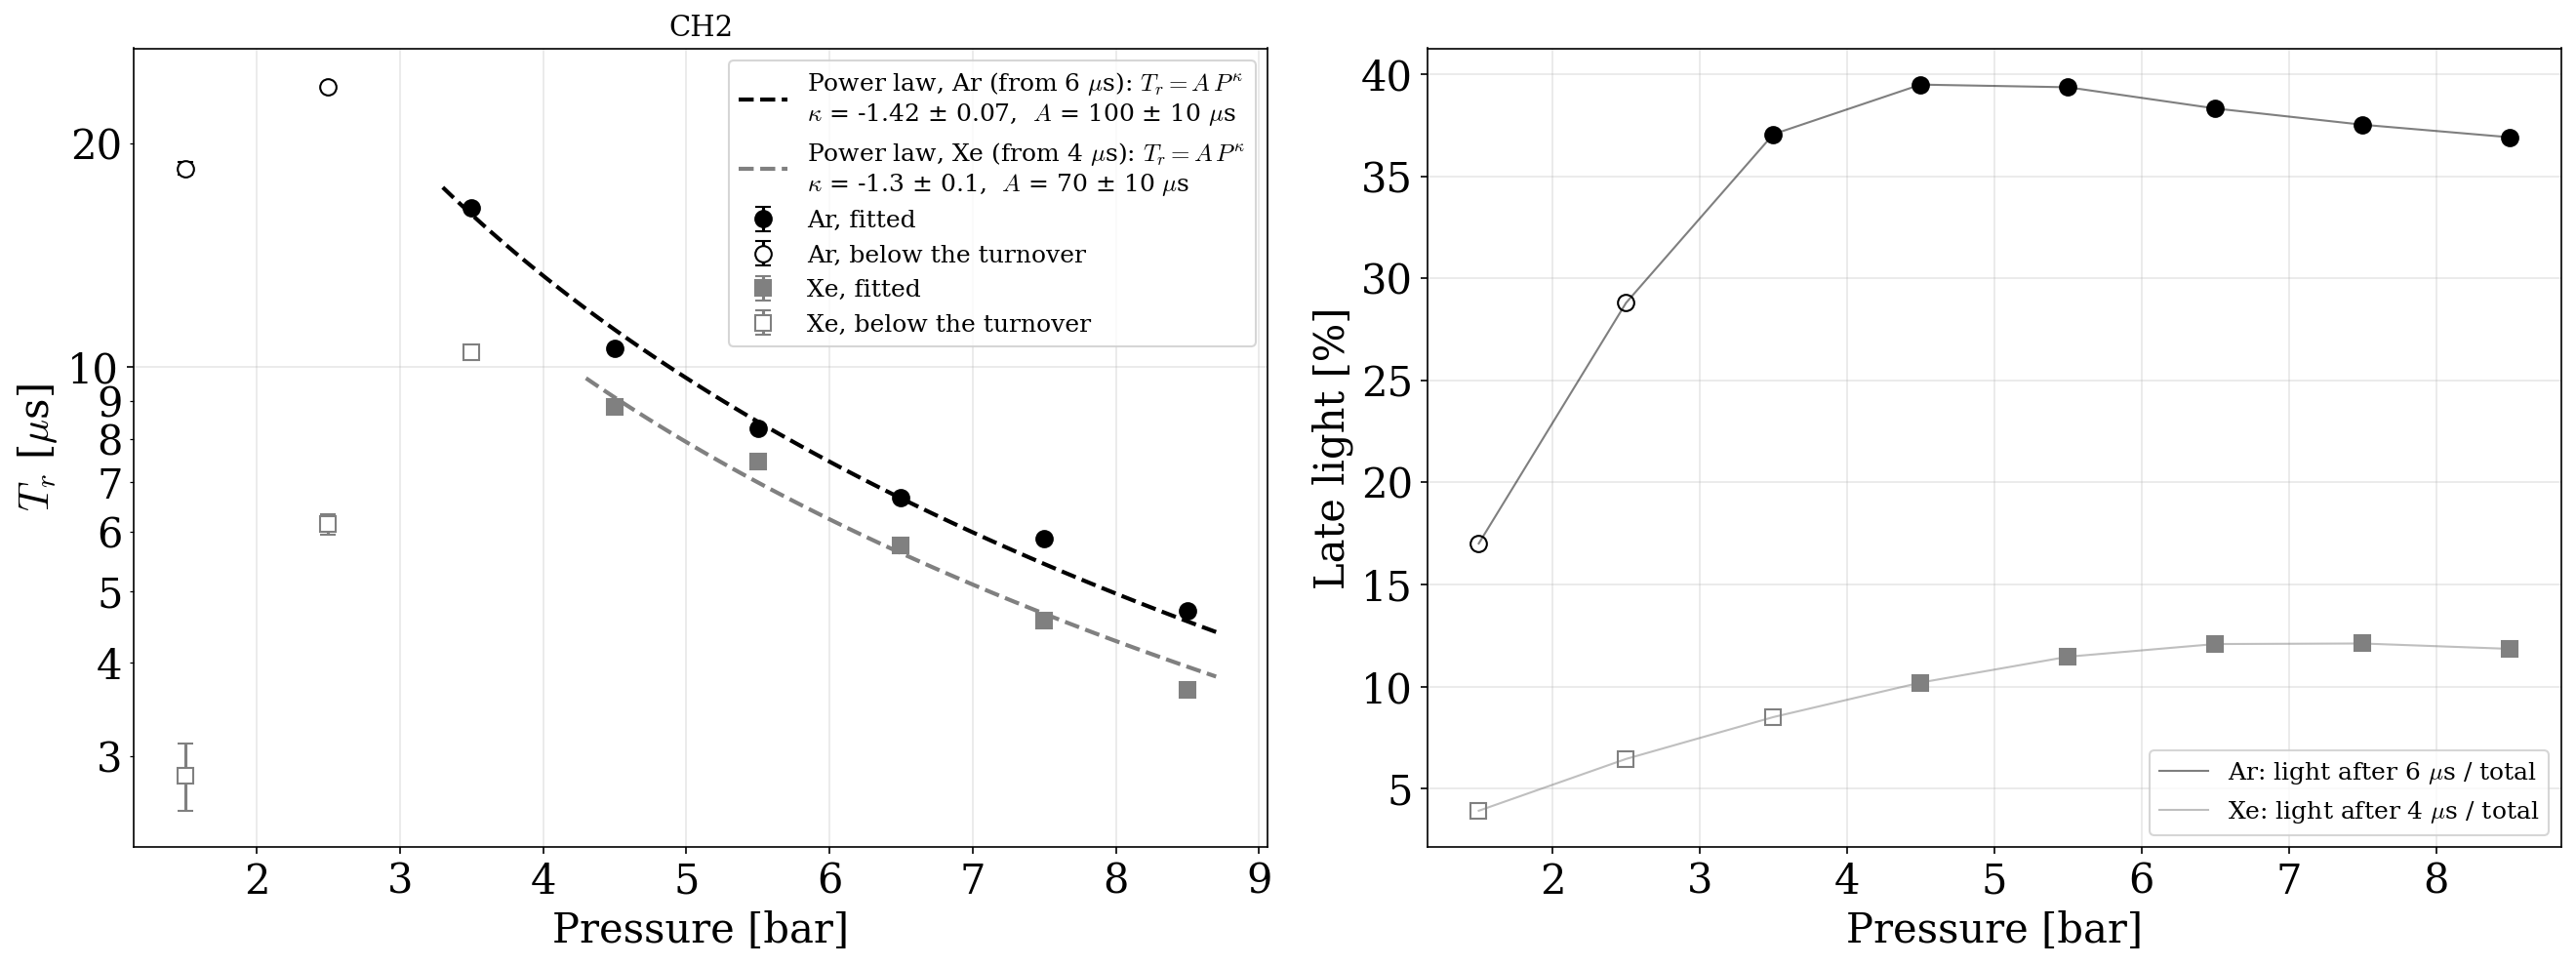

In [67]:
# Where recombination stops setting the tail: T_r(P) and the share of light after the fit start, all pressures.
# Filled = decaying part (fitted), open = below the turnover. Uses the nominal fit start of each gas.
fig, (ax_tr, ax_fr) = plt.subplots(1, 2, figsize=(18, 7), dpi=150)
for gas_i, (g, marker) in enumerate((('Ar', 'o'), ('Xe', 's'))):
    color = GS_COLORS[[0, 5][gas_i]]
    d     = tr_scan[g, T0_FIT_BY_GAS[g]]
    P     = np.array(sorted(d))
    T, Te = np.array([d[p][0] for p in P]) * 1e6, np.array([d[p][1] for p in P]) * 1e6
    used  = decaying_part(P, T)
    for sel, mfc, lab in ((used, color, f'{g}, fitted'), (~used, 'white', f'{g}, below the turnover')):
        ax_tr.errorbar(P[sel], T[sel], Te[sel], fmt=marker, color=color, mfc=mfc, ms=8, capsize=4, label=lab)
    (A, k), pcov = fit_power_law(P[used], T[used])
    Ae, ke = np.sqrt(np.diag(pcov))
    p_fit  = np.linspace(P[used].min() - 0.2, P[used].max() + 0.2, 100)
    ax_tr.plot(p_fit, A * p_fit**k, color=color, ls='--', lw=2,
               label=fr'Power law, {g} (from {T0_FIT_BY_GAS[g]*1e6:g} $\mu$s): $T_r = A\,P^{{\kappa}}$'
                     + '\n' + fr'$\kappa$ = {pm(k, ke)},  $A$ = {pm(A, Ae)} $\mu$s')

    # share of the light (integral of the mean waveform, mode baseline subtracted) arriving after the fit start
    frac = []
    for p in P:
        npz = np.load(f"{base}/mean_waveforms/mean_waveforms_{RUNS[g][p]}.npz", allow_pickle=True)
        t, wf = npz['time'], -npz[f"ch_{npz['channels'][ch_index]}"]
        pre   = wf[:pretrigger]
        grid  = np.linspace(pre.min(), pre.max(), 2001)
        wf    = wf - grid[np.argmax(gaussian_kde(pre)(grid))]
        late  = t >= T0_FIT_BY_GAS[g]
        frac.append(np.trapezoid(wf[late], t[late]) / np.trapezoid(wf[t >= t[pretrigger]], t[t >= t[pretrigger]]))
    frac = np.array(frac)
    for sel, mfc in ((used, color), (~used, 'white')):
        ax_fr.plot(P[sel], frac[sel] * 100, marker, color=color, mfc=mfc, ms=8, ls='none')
    ax_fr.plot(P, frac * 100, color=color, lw=1, alpha=0.5,
               label=fr'{g}: light after {T0_FIT_BY_GAS[g]*1e6:g} $\mu$s / total')

ax_tr.set(yscale='log', xlabel='Pressure [bar]', ylabel=r'$T_r$ [$\mu$s]')
ax_tr.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:g}'))   # plain numbers on the log axis
ax_tr.yaxis.set_minor_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:g}'))
ax_fr.set(xlabel='Pressure [bar]', ylabel='Late light [%]')
for a in (ax_tr, ax_fr):
    a.grid(True, alpha=0.3)
    a.legend(fontsize=font_size*0.6, loc='best')
ax_tr.set_title(channel, fontsize=font_size*0.7)
plt.tight_layout()
plt.show()

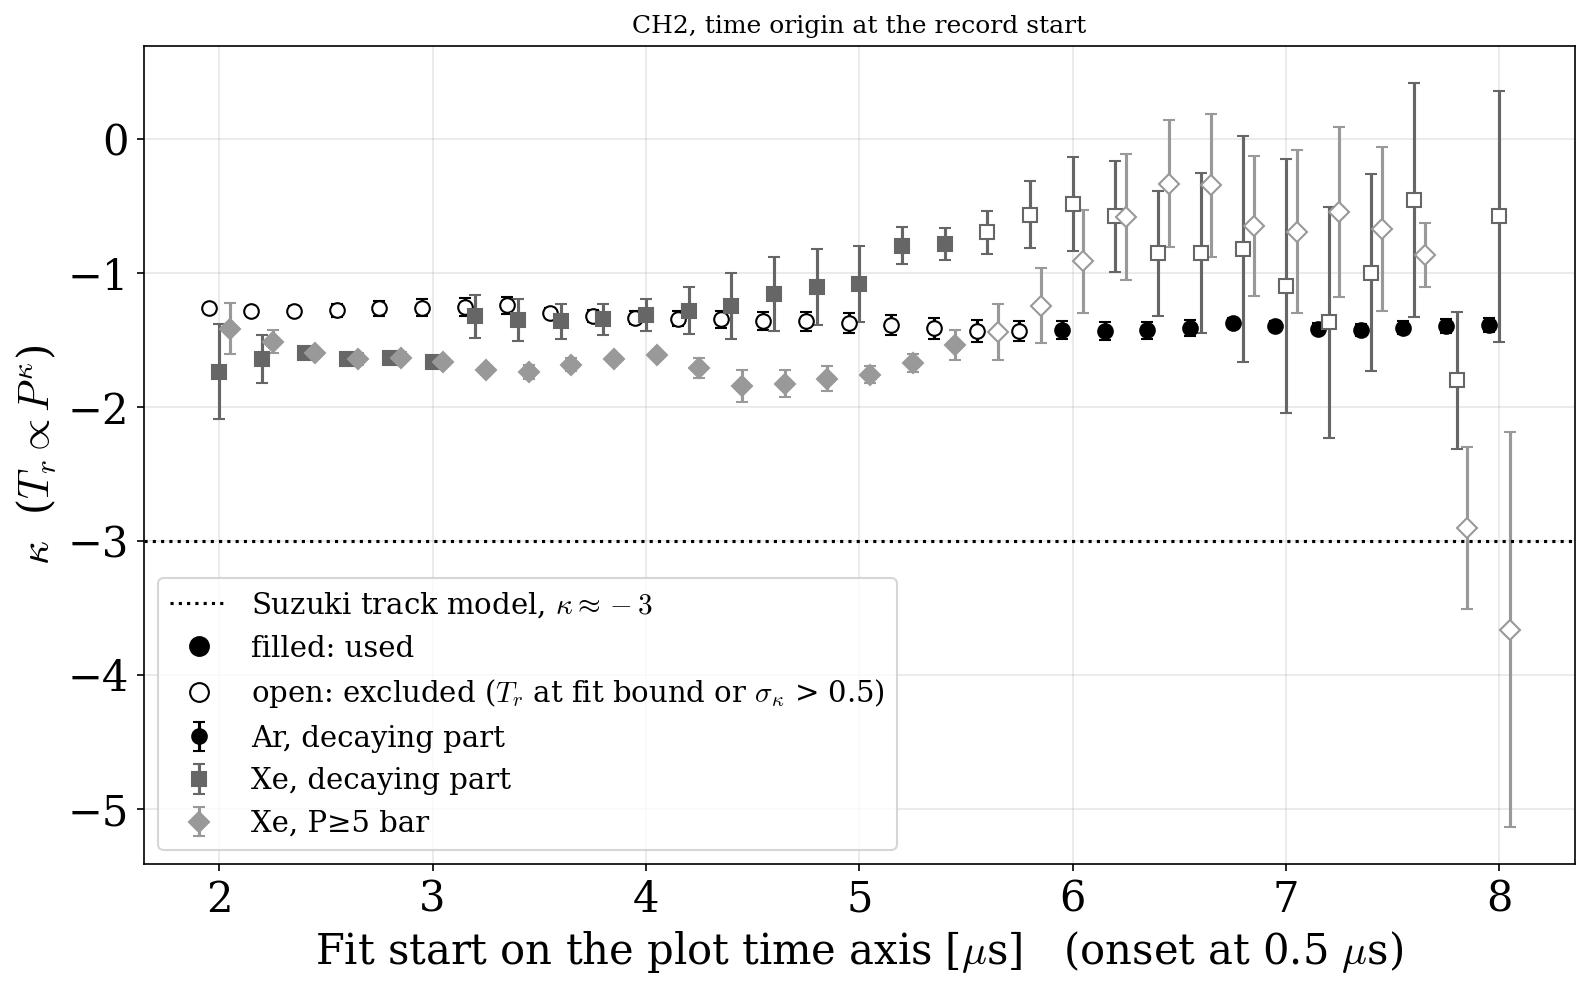

In [68]:
# kappa vs fit start for this channel. Filled: used; open: excluded (a T_r at the bound, or error > KAPPA_ERR_MAX)
fig, ax = plt.subplots(figsize=(11, 7), dpi=150)
for (name, (gas, _)), marker, shift in zip(SUBSETS.items(), ['o', 's', 'D'], [-0.05, 0, 0.05]):
    ts = np.array(FIT_STARTS[gas])
    r  = [kappa_scan[name, t] for t in ts]
    k, ke  = np.array([x['k'] for x in r]), np.array([x['k_err'] for x in r])
    capped = np.array([x['excluded'] for x in r])
    color  = GS_COLORS[[0, 4, 6][list(SUBSETS).index(name)]]
    ax.errorbar(ts[~capped]*1e6 + shift, k[~capped], ke[~capped], fmt=marker, ms=7, capsize=3, color=color, label=name)
    ax.errorbar(ts[capped]*1e6 + shift, k[capped], ke[capped], fmt=marker, ms=7, capsize=3, color=color, mfc='white')
ax.axhline(-3, color='k', ls=':', lw=1.5, label=r'Suzuki track model, $\kappa\approx-3$')
ax.set_xlabel(fr'Fit start on the plot time axis [$\mu$s]   (onset at {T_ONSET*1e6:g} $\mu$s)')
ax.set_ylabel(r'$\kappa$  ($T_r \propto P^{\kappa}$)')
ax.set_title(f'{channel}, time origin at the record start', fontsize=font_size*0.6)
ax.grid(True, alpha=0.3)
# legend entries explaining the marker fill
ax.plot([], [], 'o', color='k', ms=9, label='filled: used')
ax.plot([], [], 'o', color='k', mfc='white', ms=9,
        label=fr'open: excluded ($T_r$ at fit bound or $\sigma_\kappa$ > {KAPPA_ERR_MAX})')
ax.legend(fontsize=font_size*0.7, loc='lower left')
plt.tight_layout()
plt.show()

In [ ]:
# Cross-checks at whole-us fit starts: (1) relaxing the T_r bound to 10 x Suzuki, (2) all four channels. Takes a few minutes.
_, kappa_free = kappa_table(Tr_upper_factor=10, starts=CHECK_STARTS)
print(f'kappa, {channel}, bound 1.5x -> 10x Suzuki (only the capped fits should move)')
for name, (gas, _) in SUBSETS.items():
    print(f'  {name:12s}' + ''.join(f"  {ts*1e6:.0f}us: {kappa_scan[name, ts]['k']:+.2f} -> {kappa_free[name, ts]['k']:+.2f}"
                                    for ts in CHECK_STARTS[gas]))

kappa_ch = {f'CH{i + 1}': kappa_table(ch_idx=i, starts=CHECK_STARTS)[1] for i in range(4)}
print('\nkappa per channel (time origin: record start; * = excluded)')
for name, (gas, _) in SUBSETS.items():
    print(f'  {name}')
    for ts in CHECK_STARTS[gas]:
        print(f'    start {ts*1e6:3.0f} us:' + ''.join(
            f"  {ch} {r[name, ts]['k']:+.2f}{'*' if r[name, ts]['excluded'] else ' '}" for ch, r in kappa_ch.items()))

kappa, CH2, bound 1.5x -> 10x Suzuki (only the capped fits should move)
  Ar, decaying part  2us: -1.26 -> -1.22  3us: -1.26 -> -1.17  4us: -1.33 -> -1.31  5us: -1.37 -> -1.37  6us: -1.42 -> -1.42  7us: -1.39 -> -1.39  8us: -1.39 -> -1.39
  Xe, decaying part  2us: -1.74 -> -1.74  3us: -1.66 -> -1.66  4us: -1.31 -> -1.31  5us: -1.08 -> -1.08  6us: -0.48 -> -0.46  7us: -1.09 -> -1.04  8us: -0.58 -> -0.58
  Xe, P≥5 bar   2us: -1.41 -> -1.41  3us: -1.66 -> -1.66  4us: -1.61 -> -1.61  5us: -1.76 -> -1.76  6us: -0.91 -> -0.75  7us: -0.69 -> -0.00  8us: -3.66 -> -3.66


##  Summary figure — all pressures per channel

/tmp/ipykernel_18121/2464095444.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap      = mcm.get_cmap("gray_r")


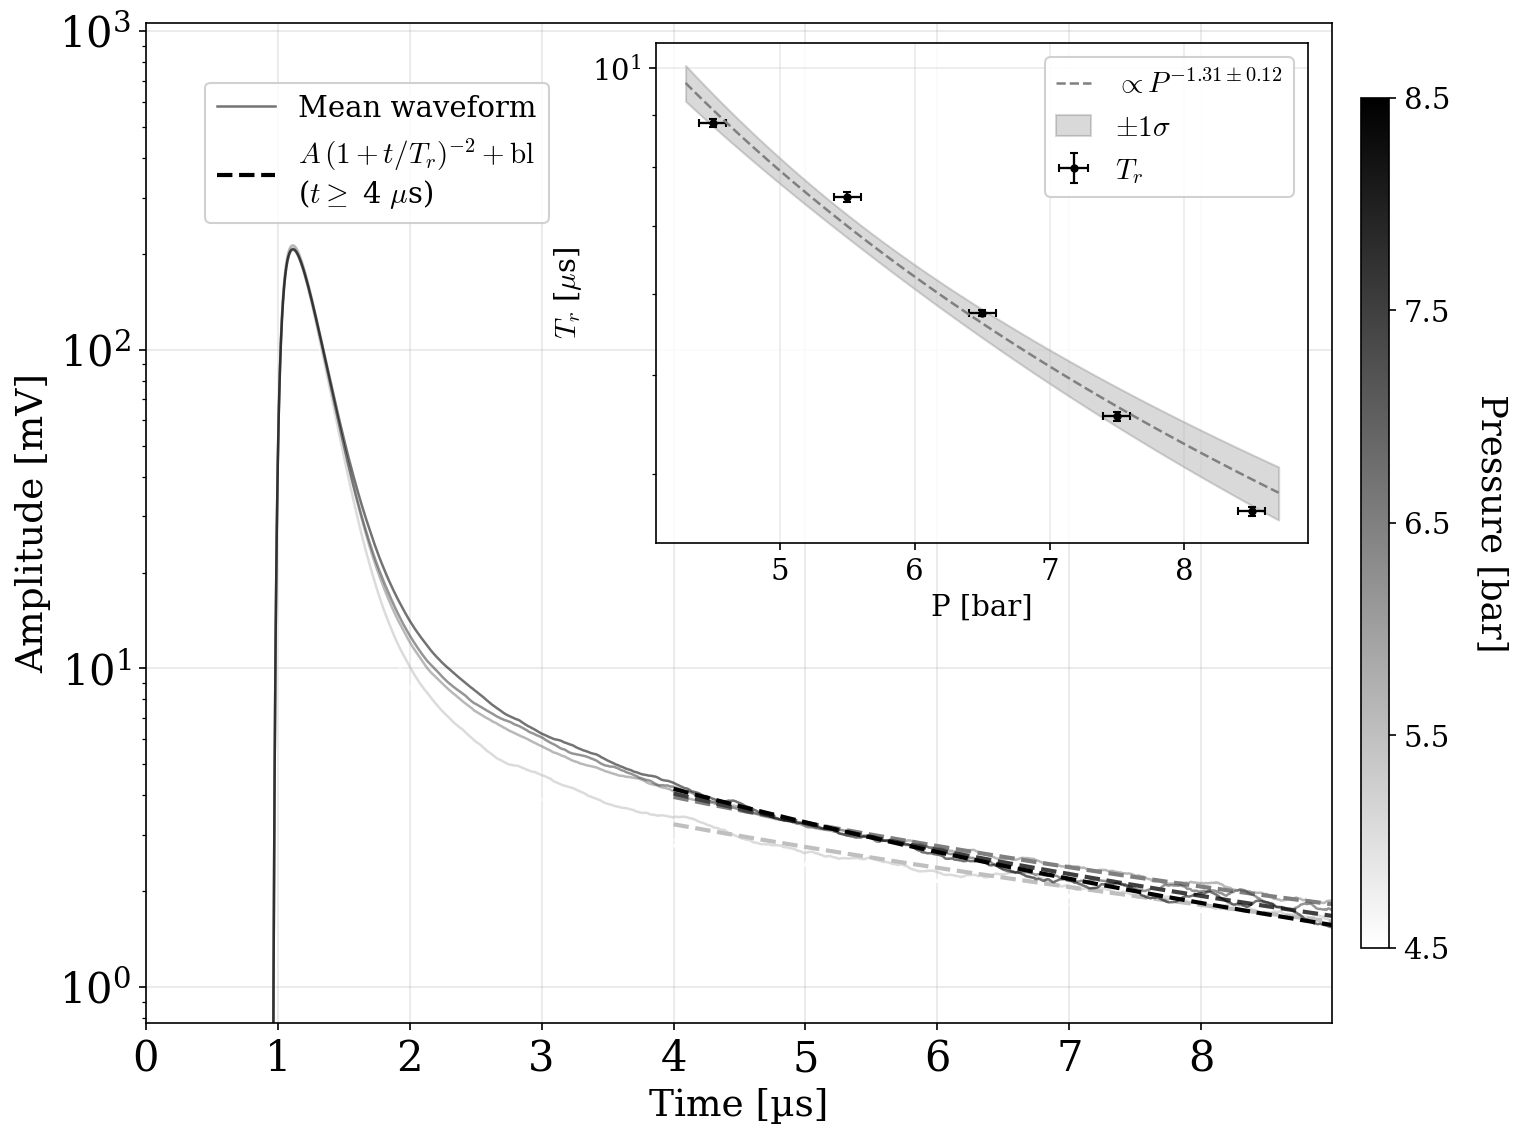

In [ ]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.cm as mcm
import matplotlib.colors as mcolors
import matplotlib.ticker

pressures_sorted = sorted(all_fits.keys())
cmap      = mcm.get_cmap("gray_r")
norm      = mcolors.Normalize(vmin=min(pressures_sorted), vmax=max(pressures_sorted))
press2col = lambda p: cmap(norm(p))

channels_ordered = sorted(
    {ch for bar_data in all_fits.values() for ch in bar_data},
    key=lambda x: int(x[2:])
)

channels_to_show = [channel]

if len(channels_to_show) > 1:
    fig_sum, axs_sum = plt.subplots(2, 2, figsize=(22, 16), dpi=150)
else:
    fig_sum, axs_sum = plt.subplots(1, 1, figsize=(11, 8), dpi=150)

# fig_sum.suptitle("CIGAR — all pressures per channel", fontsize=font_size + 2)

def fit_fn(pressure_in_bar, A, power):
    return A * pressure_in_bar ** power

for panel_i, ch in enumerate(channels_to_show):

    if np.size(axs_sum) > 1:
        ax = axs_sum.flat[panel_i]
    else:
        ax = axs_sum


    for bars in pressures_sorted:
        if ch not in all_fits.get(bars, {}): continue
        d   = all_fits[bars][ch]
        col = press2col(bars)
        ax.semilogy(d["t"]*1e6, d["wf"],               lw=1.2, alpha=0.55, color=col)
        if d["fit_ok"]:
            ax.semilogy(d["t_fit"]*1e6, d["wf_model"], lw=2.0, ls="--",   color=col)

    ax.set_xlabel("Time [µs]",       fontsize=font_size * 0.9)
    ax.set_ylabel("Amplitude [mV]",  fontsize=font_size * 0.9)
    # ax.set_title(ch,                 fontsize=font_size)
    ax.set_xlim(0, d["t"].max()*1e6)
    ax.grid(True, alpha=0.3)

    # cut the empty space below the waveforms: lower limit just below the lowest value of the tails
    # (from the fit start to the end of the plot); upper limit high enough to leave the top right
    # corner free for the T_r inset
    tail_min = min(all_fits[b][ch]["wf"][(all_fits[b][ch]["t"] >= t0_fit) & (all_fits[b][ch]["t"] <= 16e-6)].min()
                   for b in pressures_sorted if ch in all_fits.get(b, {}))
    wf_max   = max(all_fits[b][ch]["wf"].max() for b in pressures_sorted if ch in all_fits.get(b, {}))
    ax.set_ylim(0.5 * tail_min, 5 * wf_max)

    # legend for the line styles (the colour gives the pressure, see the colour bar)
    style_handles = [
        plt.Line2D([], [], color="black", lw=1.2, alpha=0.55, label="Mean waveform"),
        plt.Line2D([], [], color="black", lw=2.0, ls="--",
                   label=r"$A\,(1 + t/T_r)^{-2} + {\rm bl}$" + "\n" + fr"($t \geq$ {t0_fit*1e6:.0f} $\mu$s)"),
    ]
    ax.legend(handles=style_handles, loc=(0.05, 0.8), fontsize=font_size * 0.7, framealpha=0.9)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig_sum.colorbar(sm, ax=ax, pad=0.02, aspect=30, shrink=0.85)
    cbar.set_label("Pressure [bar]", fontsize=font_size*0.85, rotation=270, labelpad=28)
    cbar.set_ticks(pressures_sorted)
    cbar.ax.tick_params(labelsize=font_size*0.7)

    # ── inset ──
    # top right corner, above the tails
    ax_in = ax.inset_axes([0.43, 0.48, 0.55, 0.5])

    bars_list = sorted(rec_Tr.get(ch, {}).keys())
    if bars_list:
        Tr_vals = np.array([rec_Tr[ch][b][0] for b in bars_list]) * 1e6
        err_Tr  = np.array([rec_Tr[ch][b][1] for b in bars_list]) * 1e6

        bars_arr = np.array(bars_list)
        used     = decaying_part(bars_arr, Tr_vals)   # fit only above the turnover of T_r(P)
        for sel, mfc in ((used, "black"), (~used, "white")):
            ax_in.errorbar(bars_arr[sel], Tr_vals[sel], yerr=err_Tr[sel], xerr=0.1,
                           fmt="o", color="black", mfc=mfc, ms=3, lw=1.1, capsize=2)

        # --- fit: decaying part only ---
        (A_fit, power_fit), pcov = fit_power_law(bars_arr[used], Tr_vals[used])
        power_err = np.sqrt(pcov[1, 1])
        p_fit     = np.linspace(bars_arr[used].min() - 0.2, bars_arr[used].max() + 0.2, 100)
        y_fit     = fit_fn(p_fit, A_fit, power_fit)
        dfdA      = p_fit ** power_fit
        dfdpower  = A_fit * p_fit ** power_fit * np.log(p_fit)
        y_std     = np.sqrt(dfdA**2 * pcov[0,0] + dfdpower**2 * pcov[1,1] + 2 * dfdA * dfdpower * pcov[0,1])

        ax_in.plot(p_fit, y_fit, color="grey", lw=1.2, ls="--",
                   label=r"$T_r \propto P^{\kappa}$" + "\n" + fr"$\kappa$ = {pm(power_fit, power_err)}")
        ax_in.fill_between(p_fit, y_fit - y_std, y_fit + y_std,
                           color="black", alpha=0.15, label=r"$\pm1\sigma$")

    ax_in.set_xlabel(r"P [bar]",          fontsize=font_size*0.7)
    ax_in.set_ylabel(r"$T_r$ [$\mu$s]",   fontsize=font_size*0.7, color="black")
    ax_in.tick_params(labelsize=font_size*0.7)
    ax_in.set_yscale("log")
    # fix oversized minor tick labels on log axis
    ax_in.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax_in.yaxis.set_major_formatter(matplotlib.ticker.LogFormatterSciNotation(labelOnlyBase=True))
    ax_in.patch.set_facecolor("white")
    ax_in.patch.set_alpha(0.85)
    ax_in.legend(fontsize=font_size*0.7, loc="upper right",
                 framealpha=0.90, handlelength=1.2)
    ax_in.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()